# Epithelial reintegration, specimen origin and CNV sensitivity

## Imports


In [1]:
from __future__ import annotations
from pathlib import Path
import argparse
import ast
import gc
from cap.figures import (
    configure_figure_style,
    save_figure,
    save_umap_figure,
)
from cap.paths import get_paths
from cap.provenance import (
    sha256_file,
    validate_frozen_inputs,
    write_run_provenance,
)


In [2]:
import hashlib
import itertools
import json
import logging
import os


In [3]:
import re
import sys


In [4]:
import shutil
import subprocess

In [5]:
from matplotlib import colormaps
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import to_hex
from matplotlib.lines import Line2D
from scipy import stats


In [6]:
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from statsmodels.stats.multitest import multipletests


In [7]:
import anndata as ad
import h5py
import infercnvpy as cnv
import matplotlib.pyplot as plt
import numpy as np


In [8]:
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import scvi
import seaborn as sns

In [ ]:
# Configure R before importing rpy2.
r_home_value = os.environ.get("R_HOME")
if not r_home_value:
    raise RuntimeError(
        "R_HOME must be set before starting the notebook kernel."
    )

r_home = Path(r_home_value).expanduser()
if not r_home.is_dir():
    raise RuntimeError("The configured R_HOME is not an existing directory.")

if os.name == "nt":
    r_executables = (
        r_home / "bin" / "x64" / "R.exe",
        r_home / "bin" / "R.exe",
    )
    if not any(path.is_file() for path in r_executables):
        raise RuntimeError("R.exe was not found under the configured R_HOME.")

os.environ["R_HOME"] = str(r_home.resolve())
os.environ.setdefault("RPY2_CFFI_MODE", "ABI")

In [10]:
import rpy2.rinterface_lib.callbacks as rcb
import rpy2.robjects as ro
from rpy2.robjects.packages import importr
import session_info

## Paths


In [ ]:
paths = get_paths()
paths.validate_base_inputs()
validate_frozen_inputs(paths)

project = paths.root
analysis_dir = paths.run_root
data_dir = paths.data_root

annotation_dir = paths.stage_dir("02_cell_annotation")
paths.require_dir(annotation_dir, "02_cell_annotation stage")

epithelial_file = annotation_dir / "h5ad" / "epithelial.h5ad"
paths.require_file(epithelial_file, "002 manually annotated epithelial object")

meta_programme_file = paths.frozen_dir / "cancer_meta_programme_signatures.xlsx"
gencode_file = paths.gencode_file
policy_file = paths.frozen_dir / "gene_policy.json"

for path in (meta_programme_file, gencode_file, policy_file):
    paths.require_file(path, path.name)

In [13]:
import logging
logging.getLogger("fontTools.subset").setLevel(logging.WARNING)


In [ ]:
paths.require_file(epithelial_file, "002 manually annotated epithelial object")

In [ ]:
for directory in (fig_dir, df_dir, save_dir, models_dir):
    directory.mkdir(parents=True, exist_ok=True)

write_run_provenance(paths, run_dir)

input_checksums = {
    "02_cell_annotation/h5ad/epithelial.h5ad": sha256_file(epithelial_file),
    "gene_policy.json": sha256_file(paths.frozen_dir / "gene_policy.json"),
    "cancer_meta_programme_signatures.xlsx": sha256_file(
        paths.frozen_dir / "cancer_meta_programme_signatures.xlsx"
    ),
    "gencode.v50.annotation.gtf.gz": sha256_file(paths.gencode_file),
    "frozen_inputs.json": sha256_file(paths.manifest_dir / "frozen_inputs.json"),
}
(run_dir / "input_checksums.json").write_text(
    json.dumps(input_checksums, indent=2) + "\n",
    encoding="utf-8",
)

In [18]:
# CPU setting used for the portable Windows rerun.
scvi_accelerator = "cpu"


In [21]:
np.random.seed(0)


In [22]:
scvi.settings.seed = 0


Seed set to 0


In [23]:
scvi.settings.num_workers = 4


In [24]:
sc.settings.verbosity = 2


In [25]:
rcb.logger.setLevel(logging.ERROR)


In [26]:
configure_figure_style()


In [27]:
# Figure typography and export settings are configured centrally by cap.figures.


In [28]:
target_genes = ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]


In [29]:
random_seed = 0


In [30]:
n_hvg_primary = 4000


In [31]:
cnv_high_quantile = 0.95


In [32]:
infercnv_dynamic_threshold = 1.5


In [33]:
cnv_quantiles = (0.9, 0.95, 0.99)


In [34]:
n_latent = 20


In [35]:
n_layers = 2


In [36]:
gene_likelihood = "nb"


In [37]:
n_neighbors = 30


In [38]:
primary_resolution = 0.5


In [39]:
leiden_resolutions = (0.5, 1.0, 1.2, 1.5)


In [47]:
sc.settings.figdir = fig_dir


In [49]:
meta_programme_file = paths.frozen_dir / "cancer_meta_programme_signatures.xlsx"


In [50]:
gencode_file = paths.gencode_file


In [51]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


In [52]:
policy_file = paths.frozen_dir / "gene_policy.json"


In [53]:
policy_sha256 = "c4213d53e2d3209312e7781c73ed20f660e0f256042956742693c0e0375926a6"


In [54]:
def load_gene_policy(path=policy_file):
    path = Path(path)
    payload = path.read_bytes()
    digest = hashlib.sha256(payload).hexdigest()
    if digest != policy_sha256:
        raise ValueError(
            "Gene-policy checksum differs from the reviewed source snapshot"
        )
    policy = json.loads(payload)
    policy["sha256"] = digest
    return policy


In [55]:
gene_policy = load_gene_policy()


In [56]:
assert file_sha256(gencode_file) == gene_policy["gencode_v50_sha256"]


In [ ]:
STAGE = "03a_epithelial_integration"
run_dir = paths.prepare_stage(STAGE)

fig_dir = run_dir / "figures"
df_dir = run_dir / "tables"
save_dir = run_dir / "h5ad"
models_dir = run_dir / "models"
model_dir = models_dir / "scvi_epithelial_model"

for directory in (fig_dir, df_dir, save_dir, models_dir):
    directory.mkdir(parents=True, exist_ok=True)

write_run_provenance(paths, run_dir)

input_checksums = {
    "02_cell_annotation/h5ad/epithelial.h5ad": sha256_file(epithelial_file),
    "gene_policy.json": sha256_file(policy_file),
    "cancer_meta_programme_signatures.xlsx": sha256_file(meta_programme_file),
    "gencode.v50.annotation.gtf.gz": sha256_file(gencode_file),
    "frozen_inputs.json": sha256_file(paths.manifest_dir / "frozen_inputs.json"),
}
(run_dir / "input_checksums.json").write_text(
    json.dumps(input_checksums, indent=2) + "\n",
    encoding="utf-8",
)

In [57]:
for path in (meta_programme_file, gencode_file, policy_file):
    paths.require_file(path, path.name)


In [58]:
def rel(path):
    """Display repository or external-data paths without embedding local absolute paths."""
    path = Path(path).resolve()
    for base, label in ((paths.root, Path(".")), (paths.data_root, Path("CAP_DATA_ROOT"))):
        try:
            return label / path.relative_to(base)
        except ValueError:
            continue
    return Path(path.name)


## Load the epithelial compartment

In [59]:
epi = sc.read_h5ad(epithelial_file)


In [60]:
assert "cohort_selection" in epi.uns, "Input lacks the cohort-selection record; use the output from the updated upstream notebook."


In [61]:
cohort_selection = epi.uns["cohort_selection"]


In [62]:
assert not epi.obs["patient"].astype(str).isin(
    list(cohort_selection["excluded_patients"])
).any(), "An excluded donor is present in the analysis input."


In [63]:
assert epi.obs["sample"].nunique() == cohort_selection["n_selected_libraries"], "Library count differs from the upstream cohort-selection record."


In [64]:
legacy_celltypist_columns = {
    "celltypist_pal_label": "celltypist_reference_label",
    "celltypist_pal_conf": "celltypist_reference_confidence",
}


In [65]:
assert (
    epi.uns.get("annotation_mapping", {}).get("method") == "manual"
), "Use the epithelial object exported after manual annotation in 002."


In [66]:
assert epi.obs["cl_annotation"].notna().all()


In [67]:
assert epi.obs[
    "epithelial_primary"
].all(), "Input contains cells excluded from the epithelial population."


In [68]:
def feature_identities(var, policy):
    """Assign frozen HGNC IDs by stable matrix IDs, without changing var_names."""
    if not var.index.is_unique or "gene_id" not in var:
        raise ValueError(
            "Unique feature names and original Ensembl gene_id values are required"
        )
    ids = var["gene_id"].astype(str).str.split(".").str[0]
    canonical = {}
    for records in policy["symbols"].values():
        for record in records:
            if record["ensembl_id"]:
                canonical.setdefault(record["ensembl_id"], set()).add(record["hgnc_id"])
    values = []
    for identifier in ids:
        identity = policy["feature_hgnc_ids"].get(identifier)
        if identity is None:
            candidates = canonical.get(identifier, set())
            identity = next(iter(candidates)) if len(candidates) == 1 else ""
        values.append(identity)
    return pd.Series(values, index=var.index, name="hgnc_id")


In [69]:
def apply_gene_flags(adata, policy):
    """Replace broad QC prefixes with reviewed family memberships."""
    identity = feature_identities(adata.var, policy)
    audit = pd.DataFrame(
        {
            "feature_gene": adata.var_names.astype(str),
            "feature_id": adata.var["gene_id"].astype(str).to_numpy(),
            "hgnc_id": identity.to_numpy(),
        }
    )
    for flag in ["mt", "ribo", "hb"]:
        old = (
            adata.var[flag].astype(bool).to_numpy()
            if flag in adata.var
            else np.zeros(adata.n_vars, bool)
        )
        new = identity.isin(policy["families"][flag]).to_numpy()
        adata.var[flag] = new
        audit[flag + "_before"] = old
        audit[flag + "_after"] = new
    return audit


In [70]:
def require_gene_policy(adata, policy, upstream):
    record = adata.uns.get("gene_policy", {})
    if record.get("sha256") != policy["sha256"] or not record.get(
        "cell_cycle_scored", False
    ):
        raise ValueError(
            f"Input uses superseded gene definitions; rerun {upstream} with the current gene policy"
        )


In [71]:
def stamp_gene_policy(adata, policy, stage, cell_cycle_scored=None):
    previous = dict(adata.uns.get("gene_policy", {}))
    previous.update(
        {"version": policy["version"], "sha256": policy["sha256"], "stage": stage}
    )
    if cell_cycle_scored is not None:
        previous["cell_cycle_scored"] = bool(cell_cycle_scored)
    adata.uns["gene_policy"] = previous


In [72]:
require_gene_policy(epi, gene_policy, "002")


In [73]:
gene_flag_audit = apply_gene_flags(epi, gene_policy)


In [74]:
gene_flag_audit.to_csv(df_dir / "epithelial_gene_flags.csv", index=False)


In [75]:
stamp_gene_policy(epi, gene_policy, "epithelial_integration")


In [76]:
epi.obs.rename(
    columns={
        old: new
        for old, new in legacy_celltypist_columns.items()
        if old in epi.obs.columns and new not in epi.obs.columns
    },
    inplace=True,
)


In [77]:
display(
    pd.DataFrame(
        {
            "cells": [epi.n_obs],
            "genes": [epi.n_vars],
            "samples": [epi.obs["sample"].nunique()],
        }
    )
)


,cells,genes,samples
0,123382,28502,43


In [78]:
if "X_umap" in epi.obsm and "X_umap_atlas" not in epi.obsm:
    epi.obsm["X_umap_atlas"] = epi.obsm["X_umap"].copy()


In [79]:
counts = epi.layers["counts"]


In [80]:
count_values = counts.data if sp.issparse(counts) else np.asarray(counts).ravel()


In [81]:
assert np.isfinite(count_values).all()


In [82]:
assert np.allclose(count_values, np.rint(count_values))


In [83]:
baseline_positive = {
    gene: int((np.asarray(epi[:, gene].layers["counts"].todense()).ravel() > 0).sum())
    for gene in target_genes
}


In [84]:
display(pd.Series(baseline_positive, name="cells_with_raw_count"))


ROR1      1143
ROR2      2477
EGFR     12688
ERBB2    34795
EPCAM    59500
Name: cells_with_raw_count, dtype: int64

## Gene filtering and normalisation

In [85]:
n_cells_loaded = epi.n_obs


In [86]:
n_genes_loaded = epi.n_vars


In [87]:
sc.pp.filter_genes(epi, min_cells=3)


filtered out 1210 genes that are detected in less than 3 cells


In [88]:
n_genes_removed = n_genes_loaded - epi.n_vars


In [89]:
n_cells_start = epi.n_obs


In [90]:
n_genes_start = epi.n_vars


In [91]:
shape_summary = pd.DataFrame(
    {
        "stage": ["loaded", "analysis object"],
        "cells": [n_cells_loaded, epi.n_obs],
        "genes": [n_genes_loaded, epi.n_vars],
    }
)


In [92]:
display(shape_summary)


,stage,cells,genes
0,loaded,123382,28502
1,analysis object,123382,27292


In [93]:
epi.layers["lognorm"] = epi.layers["log1p"].copy()


In [94]:
epi.X = epi.layers["lognorm"].copy()


In [95]:
n_cells_start = epi.n_obs


In [96]:
n_genes_start = epi.n_vars


In [97]:
assert n_cells_start == n_cells_loaded


In [98]:
assert n_genes_start == n_genes_loaded - n_genes_removed


## Highly variable genes

Binomial deviance (`scry`) computed per sample and aggregated by the maximum
across samples, so that a gene deviant in a single condition is retained.
Mitochondrial, ribosomal and haemoglobin genes are excluded before ranking.
Cell-cycle genes are deliberately **not** excluded here: proliferation is a
tumour-associated epithelial state of interest.

In [99]:
%load_ext rpy2.ipython


In [100]:
%%R
.libPaths(unique(c(Sys.getenv("R_LIBS_USER"), .libPaths())))
suppressPackageStartupMessages({
    library(Matrix)
    library(SingleCellExperiment)
    library(scry)})

In [101]:
def scipy_to_dgc(matrix):
    matrix = sp.csc_matrix(matrix)
    return ro.r["new"](
        "dgCMatrix",
        i=ro.IntVector(matrix.indices),
        p=ro.IntVector(matrix.indptr),
        x=ro.FloatVector(matrix.data),
        Dim=ro.IntVector(matrix.shape),
    )


In [102]:
samples = epi.obs["sample"].astype(str).unique().tolist()


In [103]:
deviance = pd.DataFrame(index=epi.var_names, columns=samples, dtype=float)


In [104]:
for sample in samples:
    sub = epi[epi.obs["sample"].astype(str) == sample]
    ro.globalenv["raw_counts"] = scipy_to_dgc(sub.layers["counts"].T)
    ro.globalenv["gene_names"] = ro.StrVector(sub.var_names.tolist())
    ro.globalenv["cell_names"] = ro.StrVector(sub.obs_names.tolist())
    ro.r(
        """
        rownames(raw_counts) <- gene_names
        colnames(raw_counts) <- cell_names

        sce <- SingleCellExperiment(assays = list(counts = raw_counts))
        sce <- devianceFeatureSelection(sce)

        binomial_deviance <- rowData(sce)$binomial_deviance
    """
    )
    deviance[sample] = np.asarray(ro.r["binomial_deviance"])
    ro.r("rm(raw_counts, sce, binomial_deviance); gc()")
    print(f"{sample}: {sub.n_obs:,} cells")


GSM4909295_ER-AH0319: 562 cells
GSM4909296_ER-MH0001: 5,064 cells
GSM4909302_ER-MH0025: 3,673 cells
GSM4909305_ER-MH0029-7C: 2,034 cells
GSM4909306_ER-MH0029-9C: 5,803 cells
GSM4909300_ER-MH0032: 497 cells
GSM4909307_ER-MH0040: 4,991 cells
GSM4909301_ER-MH0042: 2,701 cells
GSM4909309_ER-MH0043-T: 2,582 cells
GSM4909311_ER-MH0056-T: 2,908 cells
GSM4909313_ER-MH0064-T: 2,932 cells
GSM4909297_ER-MH0125: 5,462 cells
GSM4909303_ER-MH0151: 713 cells
GSM4909304_ER-MH0163: 5,060 cells
GSM4909315_ER-MH0167-T: 4,820 cells
GSM4909317_ER-MH0173-T: 2,602 cells
GSM4909298_ER-PM0360: 1,852 cells
GSM4909289_HER2-AH0308: 3,013 cells
GSM4909291_HER2-MH0031: 1,450 cells
GSM4909292_HER2-MH0069: 239 cells
GSM4909293_HER2-MH0161: 3,847 cells
GSM4909294_HER2-MH0176: 4,985 cells
GSM4909290_HER2-PM0337: 2,981 cells
GSM4909272_N-MH0021-Total: 1,233 cells
GSM4909268_N-MH0023-Total: 4,055 cells
GSM4909263_N-MH0064-Total: 718 cells
GSM4909266_N-MH0169-Total: 717 cells
GSM4909274_N-MH275-Total: 813 cells
GSM4909271

In [105]:
epi.var["binomial_deviance"] = deviance.max(axis=1)


In [106]:
assert epi.var["binomial_deviance"].notna().all()


In [107]:
for column in ["mt", "ribo", "hb"]:
    assert column in epi.var.columns, column


In [108]:
exclude = epi.var[["mt", "ribo", "hb"]].any(axis=1)


In [109]:
exclude |= feature_identities(epi.var, gene_policy).isin(
    gene_policy["families"]["immunoglobulin"]
)


In [110]:
ranked = epi.var.loc[~exclude, "binomial_deviance"].sort_values(ascending=False).index


In [111]:
deviant_genes = ranked[:n_hvg_primary]


In [112]:
meta_programme_sheet = pd.read_excel(meta_programme_file, sheet_name="Cancer MPs")


In [113]:
meta_programme_genes = (
    meta_programme_sheet.stack()
    .dropna()
    .astype(str)
    .str.strip()
    .loc[lambda x: x.ne("")]
    .unique()
)


In [114]:
def resolve_signature(genes, var, policy):
    """Return unique available feature names and a complete source-member audit.

    Exact original features remain preferred when consistent with the frozen
    identity. Otherwise a unique stable-ID/HGNC match is required. Ambiguities
    stop the run; absent source members remain explicit audit rows.
    """
    identities = feature_identities(var, policy)
    ids = var["gene_id"].astype(str).str.split(".").str[0]
    rows, selected = ([], [])
    for gene in dict.fromkeys(map(str, genes)):
        candidates = policy["symbols"].get(gene, [])
        hgnc_ids = {r["hgnc_id"] for r in candidates}
        expected_ids = {r["ensembl_id"] for r in candidates if r["ensembl_id"]}
        chosen, method = (None, "unavailable")
        if gene in var.index:
            identity = identities.loc[gene]
            if hgnc_ids and identity and (identity not in hgnc_ids):
                raise ValueError(
                    f"Exact feature conflicts with source identity: {gene}"
                )
            chosen, method = (gene, "exact_original_feature")
        else:
            direct = var.index[ids.isin(expected_ids)]
            matches = direct if len(direct) else var.index[identities.isin(hgnc_ids)]
            if len(matches) > 1:
                raise ValueError(
                    f"Ambiguous source-to-feature mapping: {gene}: {list(matches)}"
                )
            if len(matches) == 1:
                chosen = str(matches[0])
                method = (
                    "verified_Ensembl_ID" if len(direct) else "frozen_HGNC_identity"
                )
        duplicate = chosen is not None and chosen in selected
        if chosen is not None and (not duplicate):
            selected.append(chosen)
        rows.append(
            {
                "source_gene": gene,
                "feature_gene": chosen or "",
                "feature_id": str(ids.loc[chosen]) if chosen is not None else "",
                "hgnc_id": identities.loc[chosen] if chosen is not None else "",
                "method": (
                    "duplicate_feature_not_double_weighted" if duplicate else method
                ),
                "used": chosen is not None and (not duplicate),
            }
        )
    return (selected, pd.DataFrame(rows))


In [115]:
protected = sorted(set(target_genes) | set(meta_programme_genes))


In [116]:
protected_present, protected_mapping = resolve_signature(
    protected, epi.var, gene_policy
)


In [117]:
protected_mapping.to_csv(df_dir / "epithelial_protected_gene_mapping.csv", index=False)


In [118]:
epi.var["highly_variable_deviance"] = epi.var_names.isin(deviant_genes)


In [119]:
epi.var["highly_variable_protected"] = epi.var[
    "highly_variable_deviance"
] | epi.var_names.isin(protected_present)


In [120]:
epi.var["highly_variable"] = epi.var["highly_variable_deviance"].copy()


In [121]:
n_hvg_deviance = int(epi.var["highly_variable_deviance"].sum())


In [122]:
n_hvg_protected = int(epi.var["highly_variable_protected"].sum())


In [123]:
n_protected_added = n_hvg_protected - n_hvg_deviance


In [124]:
hvg_summary = pd.DataFrame(
    {
        "feature_set": ["primary_deviance", "protected_sensitivity"],
        "n_genes": [n_hvg_deviance, n_hvg_protected],
    }
)


In [125]:
display(hvg_summary)


,feature_set,n_genes
0,primary_deviance,4000
1,protected_sensitivity,4618


In [126]:
pd.Series(deviant_genes, name="gene").to_csv(
    df_dir / "epithelial_hvg_genes.csv", index=False
)


## inferCNV

Run inferCNV on a separate object so its gene filtering cannot alter the integration object. Genomic coordinates come from GENCODE v50 and are joined by stable Ensembl gene ID. The primary run uses infercnvpy's documented default dynamic threshold of 1.5. The normal-reference quantile sensitivity below does not test this smoothing parameter.

In [127]:
cnv_adata = ad.AnnData(
    X=epi.layers["lognorm"].copy(), obs=epi.obs.copy(), var=epi.var.copy()
)


In [128]:
print(
    f"inferCNV working object: {cnv_adata.n_obs:,} cells x {cnv_adata.n_vars:,} genes"
)


inferCNV working object: 123,382 cells x 27,292 genes


In [129]:
gtf = pd.read_csv(
    gencode_file,
    sep="\t",
    comment="#",
    header=None,
    names=[
        "chromosome",
        "source",
        "feature",
        "start",
        "end",
        "score",
        "strand",
        "frame",
        "attribute",
    ],
)


In [130]:
gencode = gtf[gtf["feature"] == "gene"].copy()


In [131]:
gencode["ensembl"] = (
    gencode["attribute"].str.extract('gene_id "([^"]+)"')[0].str.split(".").str[0]
)


In [132]:
gencode["gene_type"] = gencode["attribute"].str.extract('gene_type "([^"]+)"')[0]


In [133]:
gencode = gencode.drop_duplicates("ensembl").set_index("ensembl")


In [134]:
len(gencode)


78733

In [135]:
del gtf


In [136]:
gc.collect()


26

In [137]:
def cnv_annotation_ids(var, gencode, policy):
    """Apply only the explicitly reviewed historical SOD2 coordinate override."""
    ids = var["gene_id"].astype(str).str.split(".").str[0].copy()
    audit = []
    for item in policy["coordinate_overrides"]:
        target = item["annotation_ensembl_id"]
        if target not in gencode.index:
            raise ValueError(f"Reviewed annotation target absent: {target}")
        record = gencode.loc[target]
        if (
            record.chromosome != item["chromosome"]
            or int(record.start) != item["start"]
            or int(record.end) != item["end"]
            or (record.gene_type != "protein_coding")
        ):
            raise ValueError(
                "SOD2 coordinate override does not match the reviewed GENCODE version"
            )
        mask = ids.eq(item["source_ensembl_id"])
        ids.loc[mask] = target
        for feature in var.index[mask]:
            audit.append({"feature_gene": str(feature), **item})
    return (ids, pd.DataFrame(audit))


In [138]:
ensembl, coordinate_audit = cnv_annotation_ids(cnv_adata.var, gencode, gene_policy)


In [139]:
cnv_adata.var["cnv_annotation_id"] = ensembl.to_numpy()


In [140]:
coordinate_audit.to_csv(df_dir / "infercnv_coordinate_overrides.csv", index=False)


In [141]:
cnv_adata.var["chromosome"] = ensembl.map(gencode["chromosome"]).values


In [142]:
cnv_adata.var["start"] = ensembl.map(gencode["start"]).values


In [143]:
cnv_adata.var["end"] = ensembl.map(gencode["end"]).values


In [144]:
cnv_adata.var["gene_type"] = ensembl.map(gencode["gene_type"]).values


In [145]:
resolved = cnv_adata.var["chromosome"].notna()


In [146]:
del gencode


In [147]:
gc.collect()


28

In [148]:
(resolved.sum(), cnv_adata.n_vars)


(np.int64(26479), 27292)

In [149]:
cnv_adata.var.loc[~resolved, ["gene_id"]].to_csv(
    df_dir / "infercnv_unresolved_genes.csv"
)


In [150]:
autosomes = [f"chr{i}" for i in range(1, 23)]


In [151]:
keep = cnv_adata.var["chromosome"].isin(autosomes) & cnv_adata.var["gene_type"].eq(
    "protein_coding"
)


In [152]:
cnv_adata = cnv_adata[:, keep].copy()


In [153]:
cnv_adata.n_vars


17487

In [154]:
def cnv_family_mask(var, policy, relaxed=False):
    """Optional relaxation retains the HLA/keratin/SPRR/S100A families for sensitivity."""
    identity = feature_identities(var, policy)
    if relaxed:
        excluded = set(policy["families"]["ribo"]) | set(
            policy["families"]["immunoglobulin"]
        )
    else:
        excluded = set(policy["families"]["cnv_expression_confounds"])
    return identity.isin(excluded).to_numpy()


In [155]:
problematic = cnv_family_mask(cnv_adata.var, gene_policy)


In [156]:
family_audit = pd.DataFrame(
    {
        "gene": cnv_adata.var_names,
        "gene_id": cnv_adata.var["gene_id"].to_numpy(),
        "excluded_primary": problematic,
        "excluded_relaxed": cnv_family_mask(cnv_adata.var, gene_policy, relaxed=True),
    }
)


In [157]:
family_audit.to_csv(df_dir / "infercnv_family_filter_audit.csv", index=False)


In [158]:
problematic.sum()


np.int64(183)

In [159]:
cnv_adata = cnv_adata[:, ~problematic].copy()


In [160]:
sc.pp.filter_genes(cnv_adata, min_cells=100)


filtered out 2434 genes that are detected in less than 100 cells


In [161]:
cnv_adata.n_vars


14870

In [162]:
cnv_adata.var["chromosome"] = cnv_adata.var["chromosome"].astype(str)


In [163]:
cnv_adata.var["chr_num"] = (
    cnv_adata.var["chromosome"].str.replace("chr", "", regex=False).astype(int)
)


In [164]:
order = cnv_adata.var.sort_values(["chr_num", "start"]).index


In [165]:
cnv_adata = cnv_adata[:, order].copy()


In [166]:
assert cnv_adata.var_names.is_unique


In [167]:
assert (np.diff(cnv_adata.var["chr_num"].to_numpy()) >= 0).all()


In [168]:
reference = cnv_adata[cnv_adata.obs["condition"] == "N"].copy()


In [169]:
print(
    f"reference cells: {reference.n_obs:,} from {reference.obs['sample'].nunique()} samples"
)


reference cells: 26,363 from 13 samples


In [170]:
cnv_adata.obs["cnv_score"] = np.nan


In [171]:
cnv_adata.obs["cnv_signal"] = np.nan


In [172]:
x_cnv_full = None


In [173]:
failures = []


In [174]:
cnv_samples = cnv_adata.obs["sample"].astype(str).unique().tolist()


In [175]:
len(cnv_samples)


43

In [176]:
for sample in cnv_samples:
    print(f"\n{sample}")
    target = refs = combined = None
    try:
        target = cnv_adata[cnv_adata.obs["sample"].astype(str) == sample].copy()
        condition = str(target.obs["condition"].iloc[0])
        if condition == "N":
            refs = reference[reference.obs["sample"].astype(str) != sample].copy()
        else:
            refs = reference.copy()
        assert refs.n_obs > 0
        refs.obs["cnv_reference"] = "reference"
        target.obs["cnv_reference"] = "query"
        combined = sc.concat([refs, target], join="inner", merge="same")
        print(f"  {condition}: {target.n_obs:,} query, {refs.n_obs:,} reference")
        cnv.tl.infercnv(
            combined,
            reference_key="cnv_reference",
            reference_cat=["reference"],
            window_size=100,
            step=10,
            dynamic_threshold=infercnv_dynamic_threshold,
            exclude_chromosomes=("chrX", "chrY"),
            n_jobs=1,
        )
        x_cnv = combined.obsm["X_cnv"]
        x_cnv = x_cnv.toarray() if sp.issparse(x_cnv) else np.asarray(x_cnv)
        x_cnv = x_cnv.astype(np.float32)
        query = combined.obs["cnv_reference"].eq("query").to_numpy()
        query_names = combined.obs_names[query]
        x_query = x_cnv[query]
        chr_pos = sorted(combined.uns["cnv"]["chr_pos"].items(), key=lambda kv: kv[1])
        n_windows = x_query.shape[1]
        chr_labels = np.empty(n_windows, dtype=object)
        for i, (chrom, start) in enumerate(chr_pos):
            end = chr_pos[i + 1][1] if i + 1 < len(chr_pos) else n_windows
            chr_labels[start:end] = chrom
        chrom_scores = []
        chrom_weights = []
        for chrom in pd.unique(chr_labels):
            idx = np.flatnonzero(chr_labels == chrom)
            chrom_scores.append(np.sqrt(np.mean(x_query[:, idx] ** 2, axis=1)))
            chrom_weights.append(len(idx))
        chrom_scores = np.column_stack(chrom_scores)
        chrom_weights = np.asarray(chrom_weights, dtype=float)
        chrom_weights /= chrom_weights.sum()
        cnv_score = np.average(chrom_scores, axis=1, weights=chrom_weights)
        cnv_signal = np.max(np.abs(x_query), axis=1)
        cnv_adata.obs.loc[query_names, "cnv_score"] = cnv_score
        cnv_adata.obs.loc[query_names, "cnv_signal"] = cnv_signal
        if x_cnv_full is None:
            x_cnv_full = np.full((cnv_adata.n_obs, n_windows), np.nan, dtype=np.float32)
        if "cnv" not in cnv_adata.uns:
            cnv_adata.uns["cnv"] = dict(combined.uns["cnv"])
        x_cnv_full[cnv_adata.obs_names.get_indexer(query_names)] = x_query
        print(f"  median burden {np.median(cnv_score):.4f}")
    except Exception as error:
        print(f"  failed: {error}")
        failures.append({"sample": sample, "error": str(error)})
    finally:
        del target, refs, combined
        gc.collect()



GSM4909295_ER-AH0319
  ER+: 562 query, 26,363 reference


  0%|          | 0/6 [00:00<?, ?it/s]

  median burden 0.0441

GSM4909296_ER-MH0001
  ER+: 5,064 query, 26,363 reference


  0%|          | 0/7 [00:00<?, ?it/s]

  median burden 0.0329

GSM4909302_ER-MH0025
  ER+: 3,673 query, 26,363 reference


  0%|          | 0/7 [00:00<?, ?it/s]

... (77 outputs left out)

  0%|          | 0/6 [00:00<?, ?it/s]

  median burden 0.0310

GSM4909287_TN-B1-Tum0554
  TN: 2,626 query, 26,363 reference


  0%|          | 0/6 [00:00<?, ?it/s]

  median burden 0.0394


In [177]:
failures = pd.DataFrame(failures)


In [178]:
if not failures.empty:
    failures.to_csv(df_dir / "infercnv_failed_samples.csv", index=False)
    raise RuntimeError(f"inferCNV failed for {len(failures)} sample(s)")


In [179]:
assert cnv_adata.obs[["cnv_score", "cnv_signal"]].notna().all().all()


In [180]:
display(pd.DataFrame({"infercnv_samples_completed": [len(cnv_samples)]}))


,infercnv_samples_completed
0,43


In [181]:
valid = cnv_adata.obs[["cnv_score", "total_counts"]].dropna()


In [182]:
r = np.corrcoef(valid["cnv_score"], valid["total_counts"])[0, 1]


In [183]:
display(pd.DataFrame({"cnv_score_vs_total_counts_r": [r]}).round(3))


,cnv_score_vs_total_counts_r
0,-0.236


In [184]:
cnv_adata.obs.groupby("condition", observed=True)["cnv_score"].describe().round(4)


,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
N,26363.0,0.0259,0.0101,0.0004,0.0183,0.0271,0.0333,0.0662
TN,26248.0,0.0380,0.0096,0.0010,0.0316,0.0382,0.0445,0.1657
HER2+,16515.0,0.0366,0.0082,0.0041,0.0314,0.0364,0.0416,0.1014
ER+,54256.0,0.0360,0.0071,0.0016,0.0316,0.0359,0.0403,0.0899


## Specimen origin and CNV-high sensitivity

The primary population definition follows specimen origin. Epithelial cells
from ER+, HER2+ and TN specimens are labelled `tumour_derived`; this does not
imply that every cell is malignant. Normal-tissue epithelial cells provide the
reference population.

`cnv_high` is a technical flag applied to every epithelial cell whose inferred
CNV burden exceeds the 95th percentile of normal epithelium. The conjunction
of tumour origin and this flag is stored as `tumour_derived_cnv_high`. This is a
conservative CNV-enriched subgroup, not a classification of every tumour-derived cell.

G1-restricted summaries assess whether cell-cycle transcription
materially affects the CNV-high sensitivity analysis.

In [185]:
condition_values = cnv_adata.obs["condition"].astype(str)


In [186]:
phase_values = cnv_adata.obs["phase"].astype(str)


In [187]:
normal_mask = condition_values.eq("N")


In [188]:
normal_scores = cnv_adata.obs.loc[normal_mask, "cnv_score"]


In [189]:
normal_g1_scores = cnv_adata.obs.loc[normal_mask & phase_values.eq("G1"), "cnv_score"]


In [190]:
cnv_high_threshold = float(normal_scores.quantile(cnv_high_quantile))


In [191]:
cnv_high_threshold_g1 = float(normal_g1_scores.quantile(cnv_high_quantile))


In [192]:
cnv_adata.obs["tumour_derived"] = condition_values.ne("N")


In [193]:
cnv_adata.obs["cnv_high"] = cnv_adata.obs["cnv_score"].gt(cnv_high_threshold)


In [194]:
cnv_adata.obs["tumour_derived_cnv_high"] = (
    cnv_adata.obs["tumour_derived"] & cnv_adata.obs["cnv_high"]
)


In [195]:
cnv_adata.obs["g1_cell"] = phase_values.eq("G1")


In [196]:
cnv_adata.obs["tumour_derived_cnv_high_g1"] = (
    cnv_adata.obs["tumour_derived_cnv_high"] & cnv_adata.obs["g1_cell"]
)


In [197]:
origin_call = np.where(
    condition_values.eq("N"), "normal-tissue epithelium", "tumour-derived epithelium"
)


In [198]:
origin_order = ["normal-tissue epithelium", "tumour-derived epithelium"]


In [199]:
cnv_adata.obs["specimen_origin"] = pd.Categorical(origin_call, categories=origin_order)


In [200]:
population_counts = pd.crosstab(
    cnv_adata.obs["condition"], cnv_adata.obs["specimen_origin"], margins=True
)


In [201]:
display(population_counts)


specimen_origin,normal-tissue epithelium,tumour-derived epithelium,All
condition,,,
N,26363,0,26363
TN,0,26248,26248
HER2+,0,16515,16515
ER+,0,54256,54256
All,26363,97019,123382


In [202]:
rows = []


In [203]:
for quantile in cnv_quantiles:
    threshold = float(normal_scores.quantile(quantile))
    called = cnv_adata.obs["cnv_score"].gt(threshold) & cnv_adata.obs["condition"].ne(
        "N"
    )
    for condition in ["ER+", "HER2+", "TN"]:
        mask = cnv_adata.obs["condition"].eq(condition)
        rows.append(
            {
                "normal_quantile": quantile,
                "threshold": threshold,
                "condition": condition,
                "n_cells": int(mask.sum()),
                "n_cnv_high": int(called[mask].sum()),
                "cnv_high_fraction": float(called[mask].mean()),
            }
        )


In [204]:
threshold_sensitivity = pd.DataFrame(rows)


In [205]:
threshold_sensitivity.to_csv(df_dir / "infercnv_threshold_sensitivity.csv", index=False)


In [206]:
display(threshold_sensitivity.round(4))


,normal_quantile,threshold,condition,n_cells,n_cnv_high,cnv_high_fraction
0,0.90,0.0380,ER+,54256,19971,0.3681
1,0.90,0.0380,HER2+,16515,6801,0.4118
2,0.90,0.0380,TN,26248,13332,0.5079
3,0.95,0.0410,ER+,54256,11816,0.2178
4,0.95,0.0410,HER2+,16515,4491,0.2719
5,0.95,0.0410,TN,26248,10002,0.3811
6,0.99,0.0472,ER+,54256,3007,0.0554
7,0.99,0.0472,HER2+,16515,1565,0.0948
8,0.99,0.0472,TN,26248,4436,0.1690


In [207]:
cycle_cnv_summary = (
    cnv_adata.obs.groupby(["condition", "phase"], observed=True)
    .agg(
        n_cells=("cnv_score", "size"),
        median_cnv=("cnv_score", "median"),
        cnv_high_fraction=("cnv_high", "mean"),
        tumour_derived_cnv_high_fraction=("tumour_derived_cnv_high", "mean"),
    )
    .reset_index()
)


In [208]:
cycle_cnv_summary["normal_all_q95"] = cnv_high_threshold


In [209]:
cycle_cnv_summary["normal_g1_q95"] = cnv_high_threshold_g1


In [210]:
cycle_cnv_summary.to_csv(df_dir / "infercnv_cell_cycle_sensitivity.csv", index=False)


In [211]:
display(cycle_cnv_summary.round(4))


,condition,phase,n_cells,median_cnv,cnv_high_fraction,tumour_derived_cnv_high_fraction,normal_all_q95,normal_g1_q95
0,N,G1,19803,0.0255,0.0406,0.0000,0.041,0.0401
1,N,S,2656,0.0315,0.0809,0.0000,0.041,0.0401
2,N,G2M,3904,0.0306,0.0768,0.0000,0.041,0.0401
3,TN,G1,13473,0.0346,0.2342,0.2342,0.041,0.0401
4,TN,S,6848,0.0409,0.4920,0.4920,0.041,0.0401
5,TN,G2M,5927,0.0429,0.5868,0.5868,0.041,0.0401
6,HER2+,G1,11772,0.0360,0.2610,0.2610,0.041,0.0401
7,HER2+,S,2859,0.0370,0.2903,0.2903,0.041,0.0401
8,HER2+,G2M,1884,0.0374,0.3121,0.3121,0.041,0.0401
9,ER+,G1,34389,0.0356,0.2070,0.2070,0.041,0.0401


In [212]:
sample_population_summary = cnv_adata.obs.groupby(['sample', 'condition'], observed=True).agg(n_epithelial_cells=('tumour_derived', 'size'), n_tumour_derived=('tumour_derived', 'sum'), n_cnv_high=('cnv_high', 'sum'), n_tumour_derived_cnv_high=('tumour_derived_cnv_high', 'sum'), n_tumour_derived_cnv_high_g1=('tumour_derived_cnv_high_g1', 'sum'), median_cnv=('cnv_score', 'median')).reset_index()


In [213]:
sample_population_summary["tumour_derived_cnv_high_fraction"] = (
    sample_population_summary["n_tumour_derived_cnv_high"]
    / sample_population_summary["n_epithelial_cells"]
)


In [214]:
sample_population_summary["tumour_derived_cnv_high_g1_fraction"] = (
    sample_population_summary["n_tumour_derived_cnv_high_g1"]
    / sample_population_summary["n_epithelial_cells"]
)


In [215]:
sample_population_summary.sort_values(
    ["condition", "tumour_derived_cnv_high_fraction"]
).round(3)


,sample,condition,n_epithelial_cells,n_tumour_derived,n_cnv_high,n_tumour_derived_cnv_high,n_tumour_derived_cnv_high_g1,median_cnv,tumour_derived_cnv_high_fraction,tumour_derived_cnv_high_g1_fraction
0,GSM4909253_N-PM0092-Total,N,3164,0,38,0,0,0.024,0.000,0.000
1,GSM4909254_N-PM0019-Total,N,3826,0,255,0,0,0.026,0.000,0.000
2,GSM4909257_N-PM0095-Total,N,2187,0,95,0,0,0.021,0.000,0.000
3,GSM4909261_N-PM0230-Total,N,812,0,47,0,0,0.025,0.000,0.000
4,GSM4909263_N-MH0064-Total,N,718,0,55,0,0,0.031,0.000,0.000
5,GSM4909265_N-PM0233-Total,N,2044,0,100,0,0,0.024,0.000,0.000
6,GSM4909266_N-MH0169-Total,N,717,0,57,0,0,0.029,0.000,0.000
7,GSM4909268_N-MH0023-Total,N,4055,0,218,0,0,0.029,0.000,0.000
8,GSM4909270_N-PM0342-Total,N,4366,0,264,0,0,0.030,0.000,0.000
9,GSM4909271_N-MH288-Total,N,752,0,33,0,0,0.026,0.000,0.000


In [216]:
sample_population_summary.to_csv(
    df_dir / "epithelial_population_summary_by_sample.csv", index=False
)


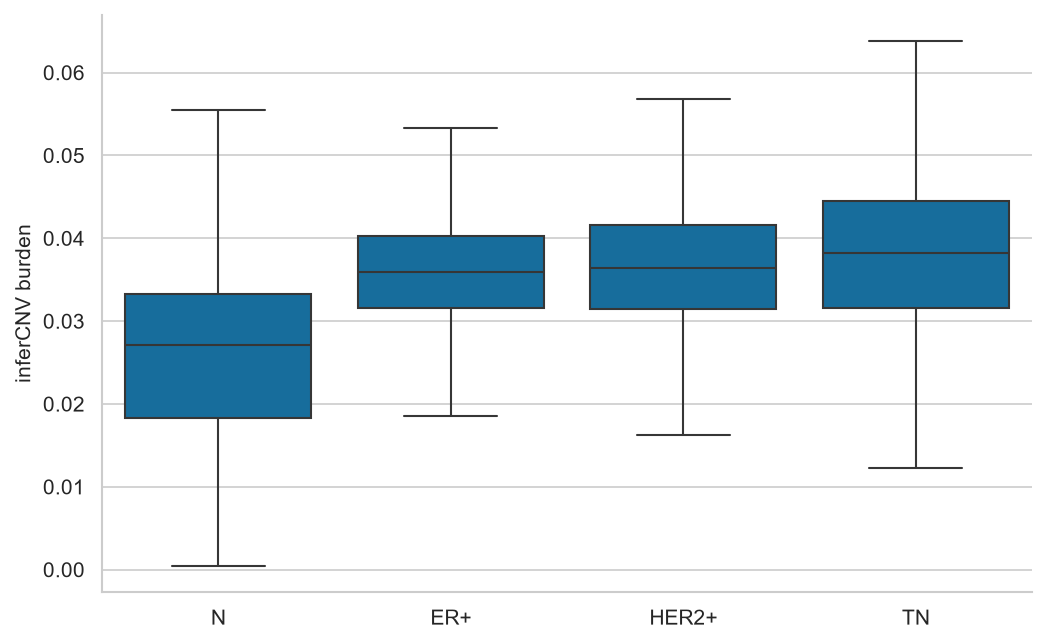

In [217]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=cnv_adata.obs,
    x="condition",
    y="cnv_score",
    order=["N", "ER+", "HER2+", "TN"],
    showfliers=False,
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("inferCNV burden")
sns.despine()
save_figure(fig, fig_dir / "infercnv_score_by_condition", close=False, overwrite=False)
plt.show()


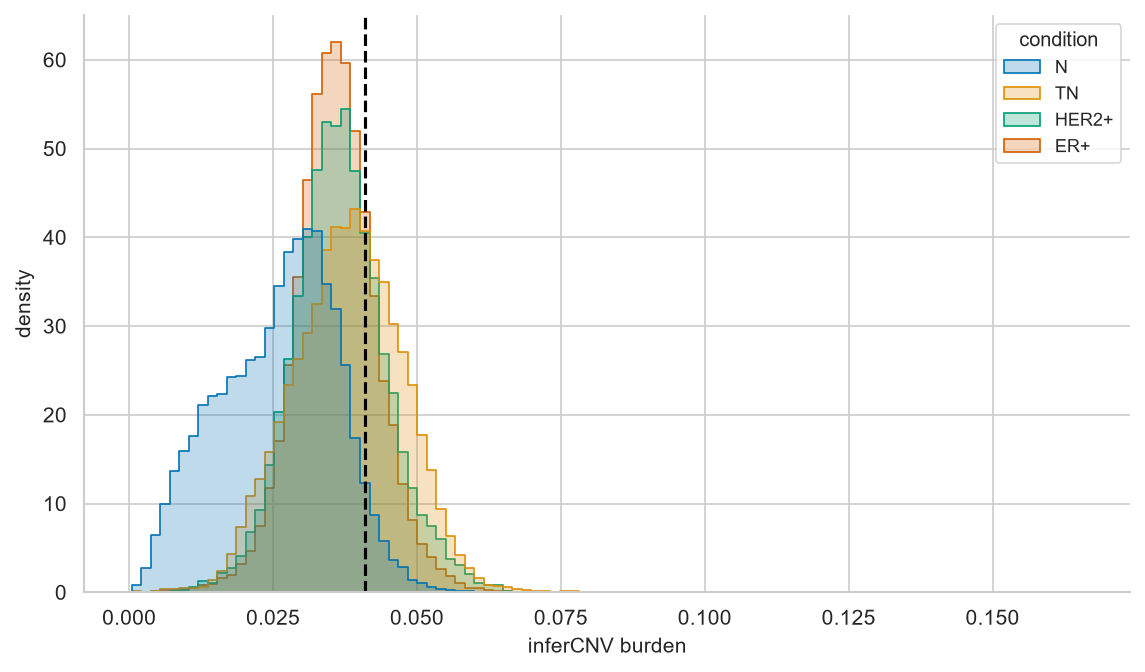

In [218]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(
    data=cnv_adata.obs,
    x="cnv_score",
    hue="condition",
    bins=100,
    stat="density",
    common_norm=False,
    element="step",
    ax=ax,
)
ax.axvline(cnv_high_threshold, linestyle="--", linewidth=1.5, color="black")
ax.set_xlabel("inferCNV burden")
ax.set_ylabel("density")
sns.despine()
save_figure(fig, fig_dir / "infercnv_cnv_high_threshold", close=False, overwrite=False)
plt.show()


In [219]:
plot_data = sample_population_summary[
    sample_population_summary["condition"].ne("N")
].copy()


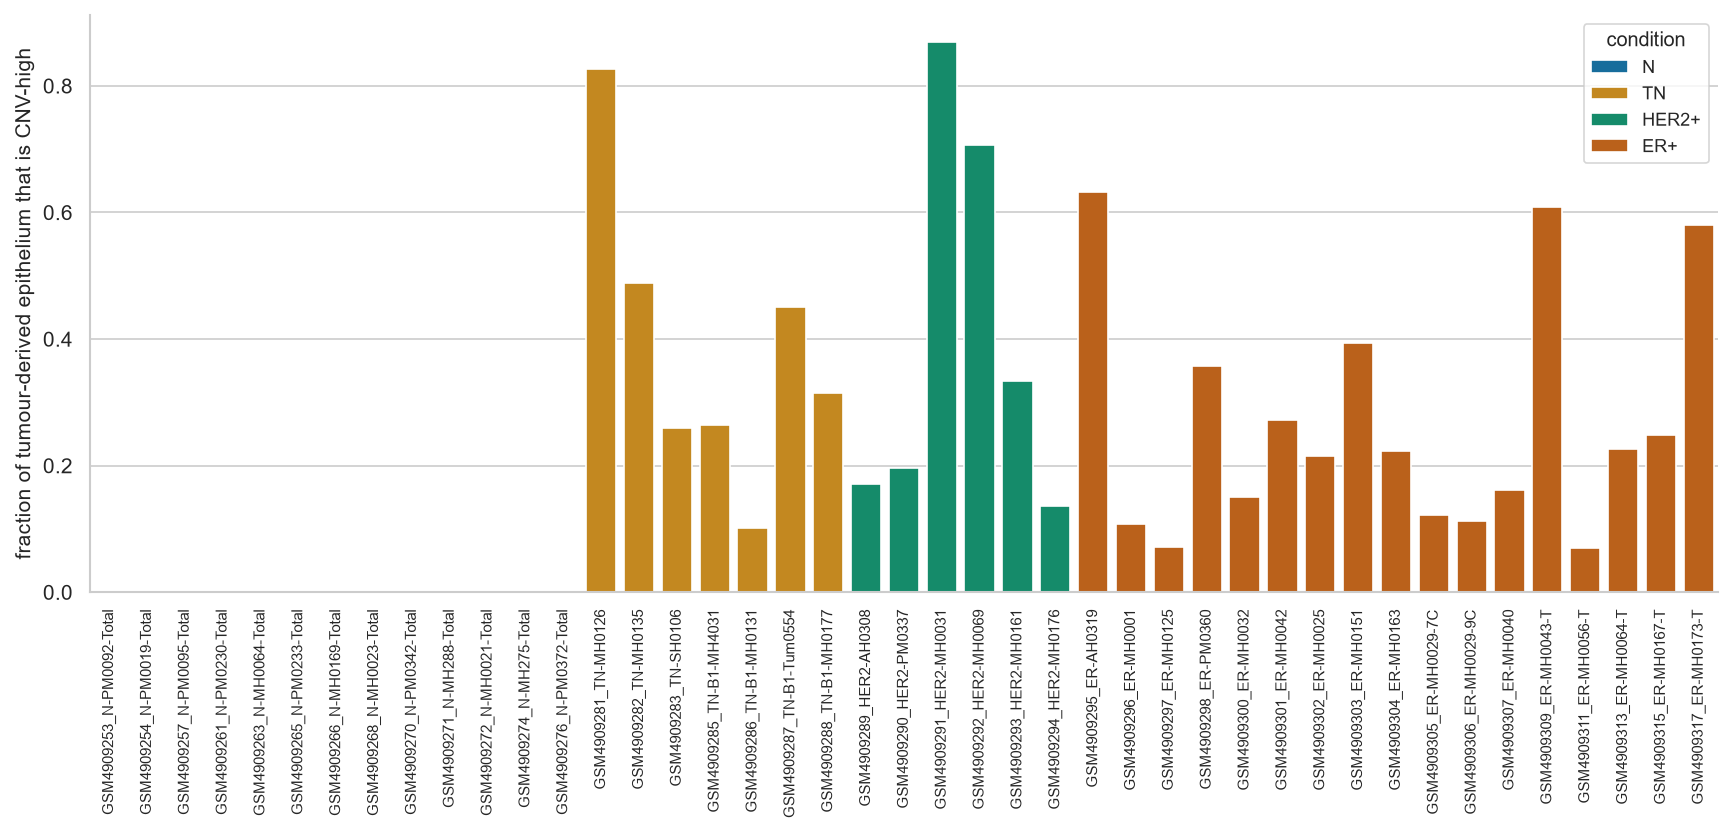

In [220]:
fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(
    data=plot_data,
    x="sample",
    y="tumour_derived_cnv_high_fraction",
    hue="condition",
    dodge=False,
    ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("fraction of tumour-derived epithelium that is CNV-high")
ax.tick_params(axis="x", rotation=90, labelsize=7)
sns.despine()
save_figure(fig, fig_dir / "tumour_derived_cnv_high_fraction_by_sample", close=False, overwrite=False)
plt.show()


In [221]:
assert epi.obs_names.equals(cnv_adata.obs_names)


In [222]:
transfer_columns = ['cnv_score', 'cnv_signal', 'tumour_derived', 'cnv_high', 'tumour_derived_cnv_high', 'g1_cell', 'tumour_derived_cnv_high_g1', 'specimen_origin']


In [223]:
for column in transfer_columns:
    epi.obs[column] = cnv_adata.obs[column].reindex(epi.obs_names)


In [224]:
boolean_columns = ['tumour_derived', 'cnv_high', 'tumour_derived_cnv_high', 'g1_cell', 'tumour_derived_cnv_high_g1']


In [225]:
for column in boolean_columns:
    epi.obs[column] = epi.obs[column].astype(bool)


In [226]:
epi.obs["specimen_origin"] = pd.Categorical(
    epi.obs["specimen_origin"], categories=origin_order
)


In [227]:
epi.uns['epithelial_population_definitions'] = {'primary_population': 'specimen origin', 'tumour_derived': 'epithelial cells from ER+, HER2+ or TN specimens', 'normal_tissue': 'epithelial cells from normal specimens', 'tumour_derived_cnv_high': 'tumour-derived and CNV burden above normal q95', 'tumour_derived_cnv_high_limitation': 'conservative CNV-enriched subgroup; does not classify all tumour-derived cells', 'cnv_method': 'infercnvpy', 'cnv_reference': 'normal epithelial cells; leave-one-sample-out for normal samples', 'gene_annotation': 'GENCODE v50 joined by Ensembl gene ID', 'expression_layer': 'log-normalised expression', 'window_size': 100, 'step': 10, 'dynamic_threshold': float(infercnv_dynamic_threshold), 'cnv_score': 'chromosome-level RMS burden weighted by window count', 'cnv_high_normal_quantile': float(cnv_high_quantile), 'cnv_high_threshold': cnv_high_threshold, 'cnv_high_threshold_g1_reference': cnv_high_threshold_g1, 'cnv_score_vs_total_counts_r': float(r)}


In [228]:
pd.DataFrame({'tumour_derived': [int(epi.obs['tumour_derived'].sum())], 'normal_tissue': [int((~epi.obs['tumour_derived']).sum())], 'cnv_high_all_epithelium': [int(epi.obs['cnv_high'].sum())], 'tumour_derived_cnv_high': [int(epi.obs['tumour_derived_cnv_high'].sum())], 'tumour_derived_cnv_high_g1': [int(epi.obs['tumour_derived_cnv_high_g1'].sum())]})


,tumour_derived,normal_tissue,cnv_high_all_epithelium,tumour_derived_cnv_high,tumour_derived_cnv_high_g1
0,97019,26363,27628,26309,13345


In [229]:
cnv_adata.obsm["X_cnv"] = x_cnv_full


In [230]:
cnv_file = save_dir / "epithelial_infercnv.h5ad"


In [231]:
if cnv_file.exists():
    raise FileExistsError("CNV output already exists; use a new run_dir for a fresh analysis.")


In [232]:
cnv_tmp_file = cnv_file.with_suffix(".h5ad.tmp")
cnv_adata.write_h5ad(cnv_tmp_file, compression="gzip")
os.replace(cnv_tmp_file, cnv_file)


In [233]:
del cnv_adata, reference, x_cnv_full


In [234]:
gc.collect()


3467

## scVI integration

In [235]:
epi_scvi = epi[:, epi.var["highly_variable"]].copy()


In [236]:
assert epi_scvi.n_obs == epi.n_obs


In [237]:
assert epi_scvi.n_vars == n_hvg_deviance


In [238]:
epi_scvi.shape


(123382, 4000)

In [239]:
scvi.model.SCVI.setup_anndata(epi_scvi, layer="counts", batch_key="sample")


In [240]:
model = scvi.model.SCVI(
    epi_scvi, n_latent=n_latent, n_layers=n_layers, gene_likelihood=gene_likelihood
)


In [241]:
del epi_scvi


In [242]:
gc.collect()


145

In [243]:
model


SCVI model with the following parameters: 
n_hidden: 128, n_latent: 20, n_layers: 2, dropout_rate: 0.1, dispersion: gene, gene_likelihood: nb, 
latent_distribution: normal.
Training status: Not Trained
Model's adata is minified?: False

In [244]:
model.train(
    max_epochs=400,
    accelerator=scvi_accelerator,
    batch_size=1024,
    early_stopping=True,
    early_stopping_patience=20,
    early_stopping_min_delta=1.0,
)


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
D:\Conda\envs\cap-rerun\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
D:\Conda\envs\cap-rerun\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
D:\Conda\envs\cap-rerun\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider inc

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Monitored metric elbo_validation did not improve in the last 20 records. Best score: 2837.829. Signaling Trainer to stop.


In [245]:
n_epochs = model.history["elbo_train"].shape[0]


In [246]:
n_epochs


190

In [247]:
model.save(str(model_dir), overwrite=False)


In [248]:
model.history["elbo_train"].to_csv(df_dir / "scvi_epithelial_history.csv")


In [249]:
latent = model.get_latent_representation()


In [250]:
assert latent.shape == (epi.n_obs, 20)


In [251]:
assert np.isfinite(latent).all()


In [252]:
epi.obsm["X_scVI"] = latent


In [253]:
latent.shape


(123382, 20)

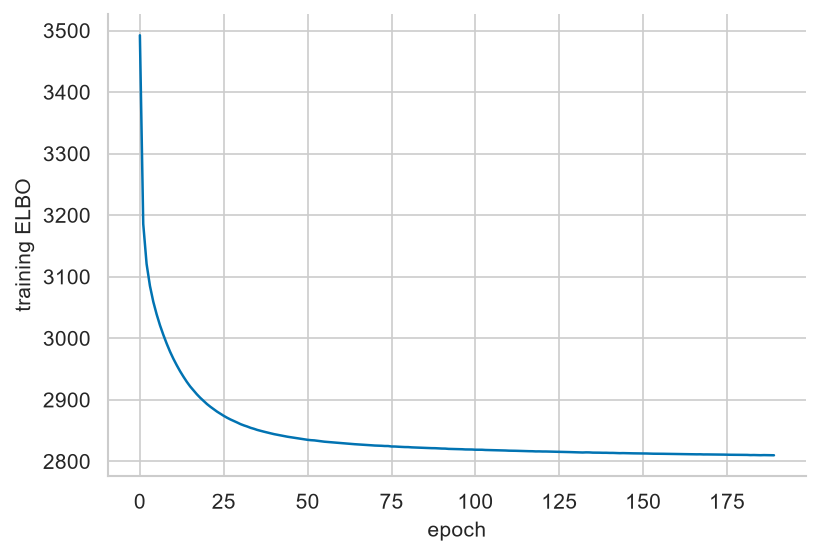

In [254]:
fig, ax = plt.subplots(figsize=(6, 4))
training_history = pd.read_csv(df_dir / "scvi_epithelial_history.csv", index_col=0)
training_history.plot(ax=ax, legend=False)
ax.set_xlabel("epoch")
ax.set_ylabel("training ELBO")
sns.despine()
save_figure(fig, fig_dir / "scvi_epithelial_elbo", close=False, overwrite=False)
plt.show()


## Neighbours, UMAP and Leiden clustering

In [255]:
sc.pp.neighbors(
    epi, use_rep="X_scVI", n_neighbors=n_neighbors, random_state=random_seed
)


computing neighbors
    finished (0:01:10)


In [256]:
sc.tl.umap(epi, random_state=random_seed)


computing UMAP
    finished (0:01:03)


In [257]:
leiden_summary = []


In [258]:
for resolution in leiden_resolutions:
    key = f"leiden_r{resolution:g}"
    sc.tl.leiden(
        epi,
        resolution=resolution,
        key_added=key,
        flavor="igraph",
        n_iterations=2,
        directed=False,
        random_state=random_seed,
    )
    leiden_summary.append(
        {"resolution": resolution, "n_clusters": epi.obs[key].nunique()}
    )


running Leiden clustering
    finished (0:00:13)
running Leiden clustering
    finished (0:00:12)
running Leiden clustering
    finished (0:00:12)
running Leiden clustering
    finished (0:00:12)


In [259]:
display(pd.DataFrame(leiden_summary))


,resolution,n_clusters
0,0.5,14
1,1.0,22
2,1.2,26
3,1.5,28


In [260]:
primary_key = f"leiden_r{primary_resolution:g}"


In [261]:
resolution_stability = pd.DataFrame(
    {
        "resolution": leiden_resolutions,
        "ari_vs_primary": [
            adjusted_rand_score(
                epi.obs[primary_key], epi.obs[f"leiden_r{resolution:g}"]
            )
            for resolution in leiden_resolutions
        ],
    }
)


In [262]:
display(resolution_stability.round(3))


,resolution,ari_vs_primary
0,0.5,1.000
1,1.0,0.422
2,1.2,0.323
3,1.5,0.320


In [263]:
epi.obs["epi_leiden"] = epi.obs[primary_key].copy()


In [264]:
epi.obs["epi_leiden"].value_counts().sort_index()


epi_leiden
0      8301
1     45348
2      6548
3        80
4      6638
5        44
6     16594
7      2558
8      8790
9     12246
10     5769
11     7094
12     3183
13      189
Name: count, dtype: int64

## Integration diagnostics

In [265]:
rng = np.random.default_rng(0)


In [266]:
n_eval = min(20000, epi.n_obs)


In [267]:
eval_idx = rng.choice(epi.n_obs, size=n_eval, replace=False)


In [268]:
z_eval = epi.obsm["X_scVI"][eval_idx]


In [269]:
obs_eval = epi.obs.iloc[eval_idx]


In [270]:
# A silhouette requires at least two manual identity categories.
bio_asw = (
    silhouette_score(z_eval, obs_eval["cl_annotation"], metric="euclidean")
    if obs_eval["cl_annotation"].nunique() > 1
    else np.nan
)

In [271]:
batch_asw = silhouette_score(z_eval, obs_eval["sample"], metric="euclidean")


In [272]:
print(f"annotation silhouette: {bio_asw:.3f}")


annotation silhouette: 0.014


In [273]:
print(f"sample silhouette:     {batch_asw:.3f}")


sample silhouette:     -0.072


In [274]:
pd.DataFrame(
    {
        "metric": ["annotation_silhouette", "sample_silhouette"],
        "value": [bio_asw, batch_asw],
    }
).to_csv(df_dir / "scvi_epithelial_integration_metrics.csv", index=False)


In [275]:
cluster_composition = pd.crosstab(
    epi.obs["epi_leiden"], epi.obs["sample"], normalize="index"
)


In [276]:
cluster_composition["top_sample_fraction"] = cluster_composition.max(axis=1)


In [277]:
cluster_composition.to_csv(df_dir / "scvi_epithelial_cluster_sample_composition.csv")


In [278]:
display(
    cluster_composition.sort_values("top_sample_fraction", ascending=False).round(3)
)


sample,GSM4909253_N-PM0092-Total,GSM4909254_N-PM0019-Total,GSM4909257_N-PM0095-Total,GSM4909261_N-PM0230-Total,GSM4909263_N-MH0064-Total,GSM4909265_N-PM0233-Total,GSM4909266_N-MH0169-Total,GSM4909268_N-MH0023-Total,GSM4909270_N-PM0342-Total,GSM4909271_N-MH288-Total,...,GSM4909304_ER-MH0163,GSM4909305_ER-MH0029-7C,GSM4909306_ER-MH0029-9C,GSM4909307_ER-MH0040,GSM4909309_ER-MH0043-T,GSM4909311_ER-MH0056-T,GSM4909313_ER-MH0064-T,GSM4909315_ER-MH0167-T,GSM4909317_ER-MH0173-T,top_sample_fraction
epi_leiden,,,,,,,,,,,,,,,,,,,,,
3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000
13,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.984,0.000,0.005,0.000,0.000,0.000,0.000,0.984
5,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.977,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.977
7,0.000,0.000,0.001,0.000,0.000,0.000,0.000,0.001,0.001,0.000,...,0.000,0.000,0.000,0.002,0.000,0.000,0.000,0.005,0.004,0.807
6,0.003,0.003,0.003,0.000,0.000,0.001,0.000,0.003,0.000,0.000,...,0.048,0.005,0.018,0.034,0.041,0.005,0.003,0.047,0.022,0.333
0,0.002,0.002,0.001,0.000,0.000,0.002,0.000,0.001,0.003,0.000,...,0.047,0.003,0.009,0.007,0.003,0.007,0.016,0.004,0.002,0.320
8,0.118,0.229,0.058,0.051,0.004,0.090,0.026,0.072,0.287,0.004,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.287
10,0.001,0.001,0.038,0.004,0.001,0.009,0.012,0.002,0.005,0.000,...,0.021,0.000,0.001,0.001,0.002,0.002,0.000,0.237,0.005,0.279
11,0.057,0.032,0.020,0.016,0.038,0.067,0.019,0.276,0.087,0.015,...,0.003,0.006,0.012,0.002,0.001,0.001,0.002,0.016,0.004,0.276


In [279]:
cluster_composition.to_csv(df_dir / "scvi_epithelial_cluster_sample_composition.csv")


In [280]:
cluster_population = epi.obs.groupby("epi_leiden", observed=True).agg(
    n_cells=("tumour_derived", "size"),
    n_tumour_derived=("tumour_derived", "sum"),
    n_tumour_derived_cnv_high=("tumour_derived_cnv_high", "sum"),
    n_tumour_derived_cnv_high_g1=("tumour_derived_cnv_high_g1", "sum"),
    median_cnv=("cnv_score", "median"),
)


In [281]:
cluster_population["tumour_derived_fraction"] = (
    cluster_population["n_tumour_derived"] / cluster_population["n_cells"]
)


In [282]:
cluster_population["tumour_derived_cnv_high_fraction"] = (
    cluster_population["n_tumour_derived_cnv_high"] / cluster_population["n_cells"]
)


In [283]:
cluster_population.sort_values(
    "tumour_derived_cnv_high_fraction", ascending=False
).round(3)


,n_cells,n_tumour_derived,n_tumour_derived_cnv_high,n_tumour_derived_cnv_high_g1,median_cnv,tumour_derived_fraction,tumour_derived_cnv_high_fraction
epi_leiden,,,,,,,
5,44,44,38,33,0.046,1.000,0.864
3,80,80,41,35,0.041,1.000,0.512
6,16594,16320,8300,340,0.041,0.983,0.500
7,2558,2549,1030,667,0.040,0.996,0.403
4,6638,6252,1956,1307,0.037,0.942,0.295
1,45348,45124,11636,8912,0.037,0.995,0.257
0,8301,8191,874,599,0.032,0.987,0.105
2,6548,6171,556,331,0.033,0.942,0.085
9,12246,2429,977,571,0.020,0.198,0.080


In [284]:
cluster_population.to_csv(df_dir / "scvi_epithelial_cluster_population_composition.csv")


In [285]:
marker_genes = [
    g
    for g in [
        "EPCAM",
        "KRT8",
        "KRT18",
        "KRT19",
        "KRT7",
        "KRT5",
        "KRT14",
        "KRT17",
        "MUC1",
    ]
    if g in epi.var_names
]


## Epithelial UMAPs

In [286]:
condition_palette = {
    "N": "#031A6B",
    "ER+": "#F46036",
    "HER2+": "#2CA02C",
    "TN": "#976391",
}


In [287]:
condition_order = ["TN", "HER2+", "ER+", "N"]


In [288]:
epi.obs["condition"] = pd.Categorical(
    epi.obs["condition"].astype(str), categories=condition_order, ordered=True
)


In [289]:
epi.uns["condition_colors"] = [condition_palette[c] for c in condition_order]


In [290]:
epi.obs["cl_annotation"] = epi.obs["cl_annotation"].astype("category")


In [291]:
epi.obs["sample_short"] = (
    epi.obs["sample_short"].astype("category").cat.remove_unused_categories()
)


In [292]:
draw_order = ["N", "TN", "HER2+", "ER+"]


In [293]:
rank = {condition: i for i, condition in enumerate(draw_order)}


In [294]:
plot_idx = epi.obs["condition"].astype(str).map(rank).sort_values().index


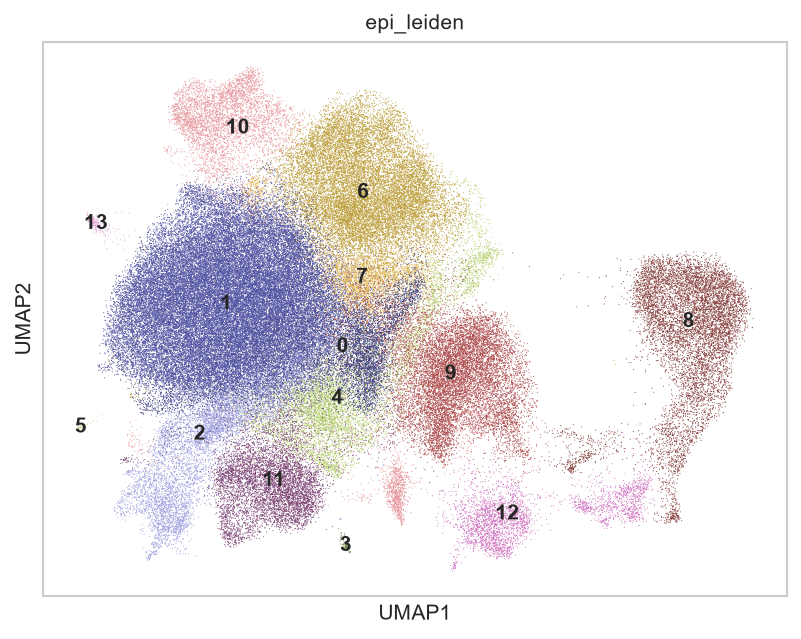

In [295]:
sc.pl.umap(epi, color="epi_leiden", palette="tab20b", legend_loc="on data", show=False)
save_umap_figure(plt.gcf(), fig_dir / "epithelial_umap_cluster_numbers", close=False, overwrite=False)
plt.show()


D:\Conda\envs\cap-rerun\Lib\site-packages\scanpy\plotting\_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


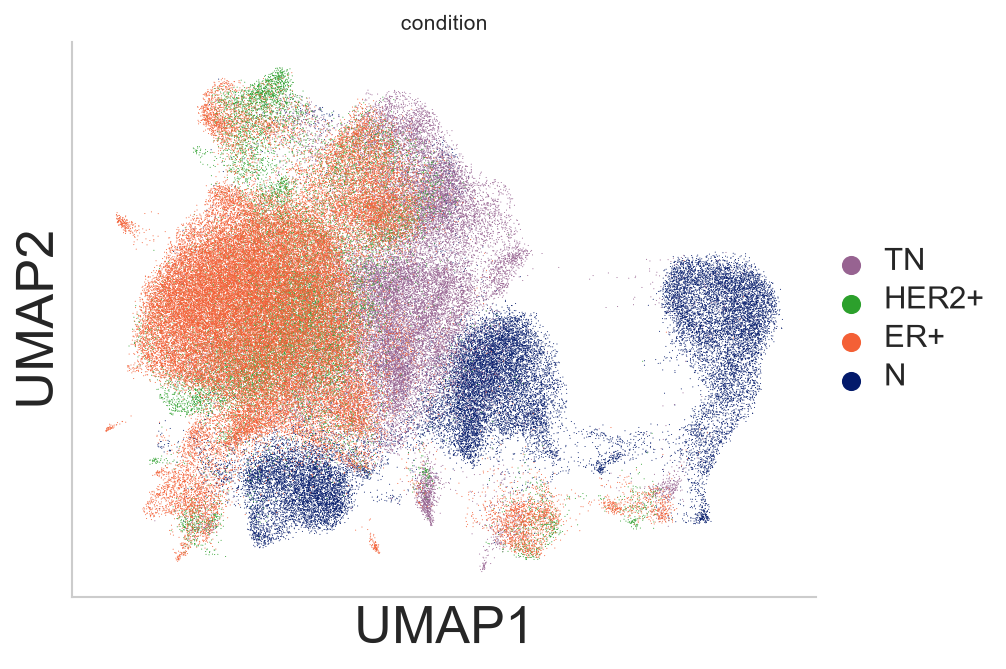

In [296]:
sc.pl.umap(
    epi[plot_idx],
    color="condition",
    palette=condition_palette,
    frameon=True,
    show=False,
)
ax = plt.gca()
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)
ax.tick_params(axis="both", labelsize=12)
legend = ax.get_legend()
if legend is not None:
    plt.setp(legend.get_texts(), fontsize=15)
    for handle in legend.legend_handles:
        handle.set_sizes([70])
save_umap_figure(plt.gcf(), fig_dir / "epithelial_umap_condition", close=False, overwrite=False)
plt.show()


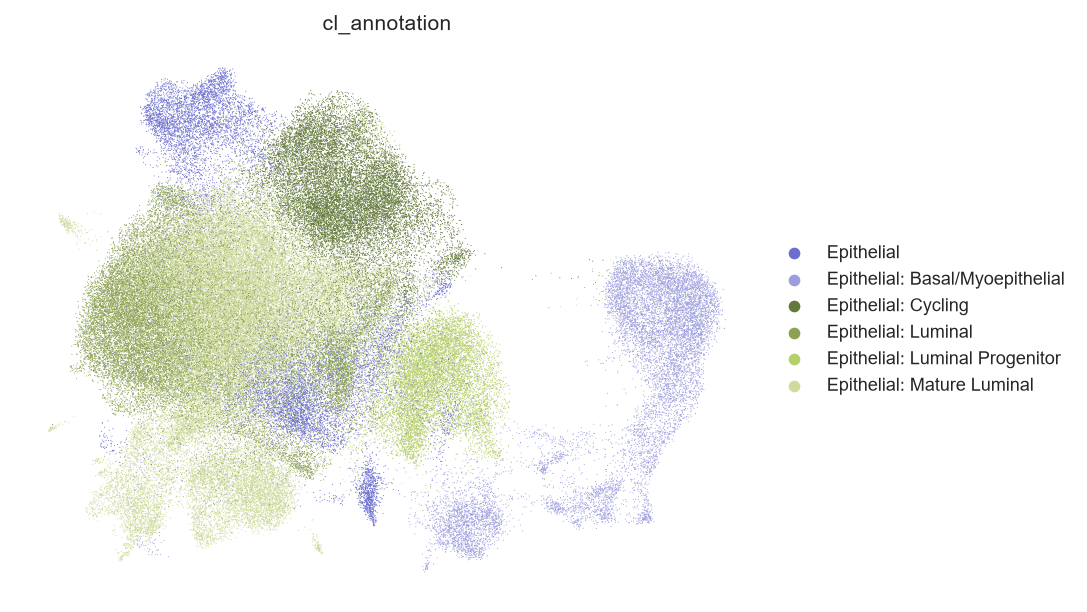

In [297]:
sc.pl.umap(epi, color="cl_annotation", frameon=False, show=False)
save_umap_figure(plt.gcf(), fig_dir / "epithelial_umap_cl_annotation", close=False, overwrite=False)
plt.show()


In [298]:
sc.tl.rank_genes_groups(
    epi,
    groupby="epi_leiden",
    layer="lognorm",
    use_raw=False,
    method="wilcoxon",
    pts=True,
    tie_correct=True,
)


ranking genes
    finished (0:08:02)


In [299]:
cluster_markers = sc.get.rank_genes_groups_df(epi, group=None)


In [300]:
cluster_markers.to_csv(df_dir / "epithelial_cluster_markers_wilcoxon.csv", index=False)


In [301]:
# Compare epithelial clusters with the current manual atlas labels.
generic_label = "Epithelial"
label_overlap = pd.crosstab(
    epi.obs["epi_leiden"], epi.obs["cl_annotation"], normalize="index"
).mul(100).round(1)
named = [label for label in label_overlap.columns if label != generic_label]

In [302]:
# Percentages use all cells in each epithelial cluster as the denominator.
# A missing generic category has zero cells; absent named labels remain undefined.
cluster_identity = pd.DataFrame({
    "n_cells": epi.obs["epi_leiden"].value_counts().reindex(label_overlap.index),
    "pct_generic": label_overlap.get(
        generic_label, pd.Series(0.0, index=label_overlap.index)
    ),
    "dominant_named": label_overlap[named].idxmax(axis=1) if named else pd.NA,
    "pct_dominant_named": label_overlap[named].max(axis=1) if named else 0.0,
})
cluster_identity["resolves_generic"] = (
    cluster_identity["pct_generic"].ge(20)
    & cluster_identity["pct_dominant_named"].ge(50)
)

In [303]:
# Export the overlap and marker evidence without changing cell labels.
top_markers = (
    cluster_markers.loc[cluster_markers["pvals_adj"] < 0.05]
    .sort_values("scores", ascending=False)
    .groupby("group", observed=True)["names"]
    .apply(lambda genes: ", ".join(genes.head(5)))
)
cluster_identity["top_markers"] = top_markers.reindex(cluster_identity.index)
cluster_identity.to_csv(df_dir / "epithelial_cluster_vs_atlas_annotation.csv")
label_overlap.to_csv(df_dir / "epithelial_cluster_annotation_overlap.csv")

In [304]:
generic_cells = epi.obs["cl_annotation"].eq(generic_label)
generic_spread = (
    epi.obs.loc[generic_cells, "epi_leiden"].value_counts().rename("n_generic_cells")
)
generic_spread = generic_spread[generic_spread > 0]
print(f"{int(generic_cells.sum()):,} cells labelled '{generic_label}' in 002 "
      f"spread over {len(generic_spread)} of {epi.obs['epi_leiden'].nunique()} new clusters")
print(f"Clusters with >50% generic labels: "
      f"{int(cluster_identity['pct_generic'].gt(50).sum())}")
print(f"Clusters with generic cells and a named majority: "
      f"{int(cluster_identity['resolves_generic'].sum())}")
display(cluster_identity.sort_values("pct_generic", ascending=False))

12,243 cells labelled 'Epithelial' in 002 spread over 12 of 14 new clusters
Clusters with >50% generic labels: 2
Clusters with generic cells and a named majority: 0


,n_cells,pct_generic,dominant_named,pct_dominant_named,resolves_generic,top_markers
epi_leiden,,,,,,
10,5769,95.5,Epithelial: Mature Luminal,2.5,False,"TMSB10, RPL22, RPL28, UBA52, RPS3A"
4,6638,56.3,Epithelial: Luminal,23.1,False,"NDRG1, NDUFA4L2, ALDH1A1, EGLN3, CASP14"
0,8301,4.2,Epithelial: Luminal,50.7,False,"SIX3, FABP7, TTYH1, AC110015.1, MT1H"
9,12246,3.7,Epithelial: Luminal Progenitor,81.6,False,"ALDH1A3, PIGR, GPAT3, CYP24A1, MMP7"
1,45348,3.1,Epithelial: Mature Luminal,53.8,False,"COX6C, CRIP1, GATA3, XBP1, AGR3"
11,7094,2.8,Epithelial: Mature Luminal,89.2,False,"TFPI, TGM2, TMEM45B, SYTL2, SAT1"
5,44,2.3,Epithelial: Mature Luminal,93.2,False,"TUBA4B, C11orf88, TEKT1, C20orf85, ANKRD66"
6,16594,2.3,Epithelial: Cycling,84.1,False,"BIRC5, UBE2C, PCLAF, CDK1, TOP2A"
2,6548,2.0,Epithelial: Mature Luminal,88.7,False,"MGP, SHISA2, XBP1, EFHD1, NEK10"


In [305]:
# Are the unresolved clusters a cell state, or a quality artefact?
cluster_quality = epi.obs.groupby("epi_leiden", observed=True).agg(
    n_cells=("total_counts", "size"),
    median_counts=("total_counts", "median"),       # low => low-complexity cells
    median_genes=("n_genes_by_counts", "median"),
    median_pct_mt=("pct_counts_mt", "median"),      # high => stressed or dying
    median_pct_ribo=("pct_counts_ribo", "median"),  # high => housekeeping-dominated
    median_top20_pct=("pct_counts_in_top_20_genes", "median"),  # high => low diversity
    median_doublet=("doublet_score", "median"),
    pct_tumour_derived=("tumour_derived", "mean"),
    median_cnv=("cnv_score", "median"),
).round(3)
cluster_quality["pct_tumour_derived"] = (100 * cluster_quality["pct_tumour_derived"]).round(1)
cluster_quality.to_csv(df_dir / "epithelial_cluster_quality.csv")
display(cluster_quality.sort_values("median_genes"))


,n_cells,median_counts,median_genes,median_pct_mt,median_pct_ribo,median_top20_pct,median_doublet,pct_tumour_derived,median_cnv
epi_leiden,,,,,,,,,
10,5769,1047.0,496.0,3.810,32.295,26.429,0.000,92.4,0.031
12,3183,2997.0,1145.0,6.214,29.426,26.023,0.008,97.3,0.025
8,8790,3090.0,1202.0,2.608,25.771,22.587,0.002,2.1,0.032
1,45348,3861.0,1375.0,6.759,26.322,27.835,0.021,99.5,0.037
4,6638,4388.0,1546.0,4.217,24.814,25.543,0.008,94.2,0.037
0,8301,7236.0,1661.0,7.285,37.731,28.825,0.011,98.7,0.032
2,6548,4618.0,1742.5,6.971,24.301,24.820,0.018,94.2,0.033
7,2558,4622.0,1743.5,5.272,23.569,19.290,0.008,99.6,0.040
5,44,3626.0,1806.5,4.323,12.571,17.179,0.005,100.0,0.046


Storing dendrogram info using `.uns['dendrogram_epi_leiden']`


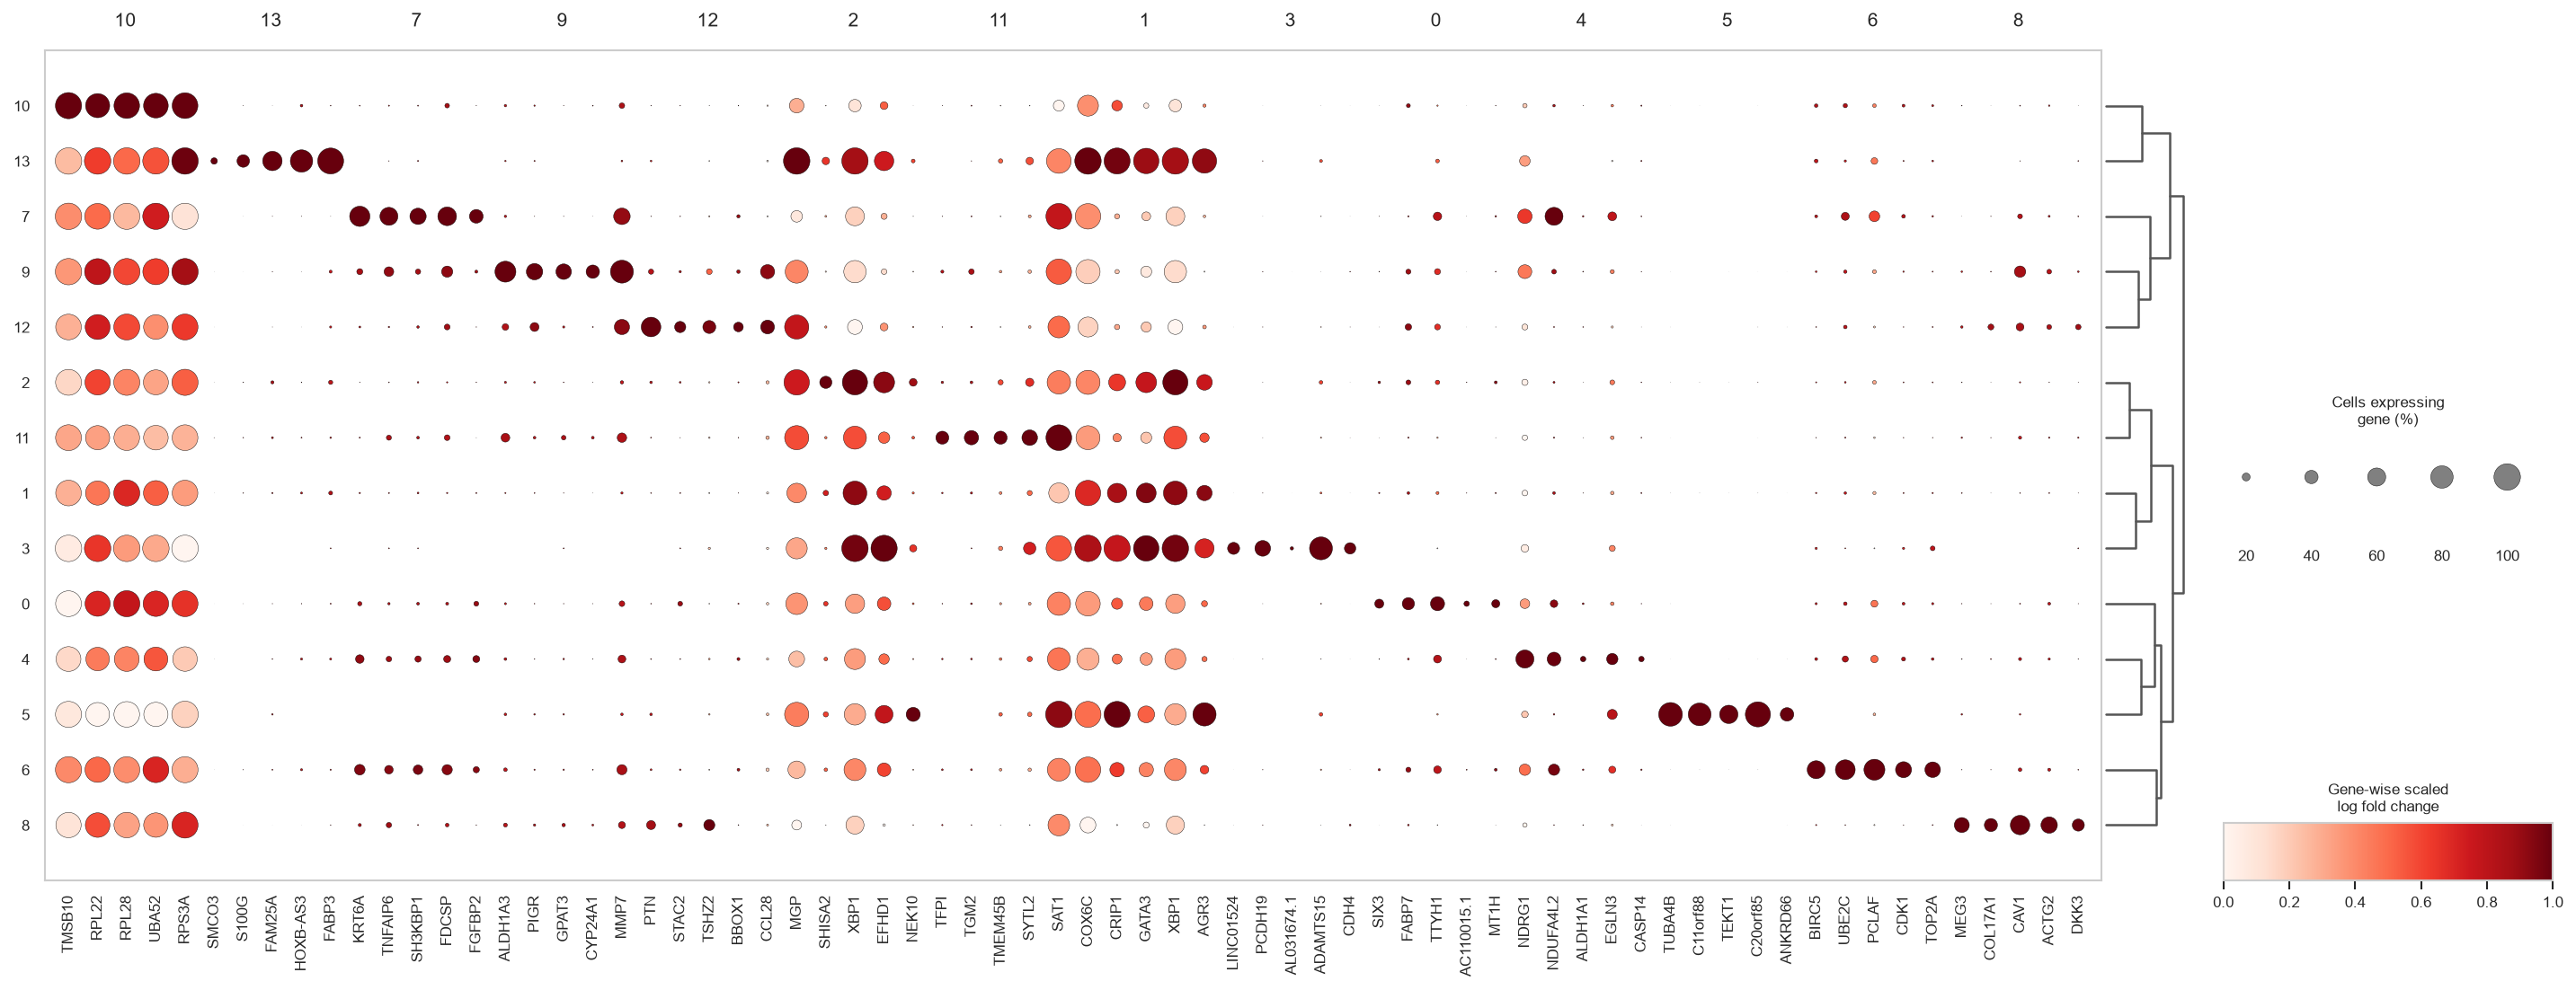

In [306]:
sc.tl.dendrogram(epi, groupby="epi_leiden", use_rep="X_scVI")

marker_dotplot = sc.pl.rank_genes_groups_dotplot(
    epi, groupby="epi_leiden", n_genes=5,
    values_to_plot="logfoldchanges", standard_scale="var",
    figsize=(24, 8), return_fig=True, show=False,
)
# The colour scale is rescaled separately for each gene.
marker_dotplot.legend(
    width=3.2, size_title="Cells expressing\ngene (%)",
    colorbar_title="Gene-wise scaled\nlog fold change",
)
marker_dotplot.make_figure()
save_figure(marker_dotplot.fig, fig_dir / "epithelial_cluster_markers_top5", close=False, overwrite=False)
plt.show()


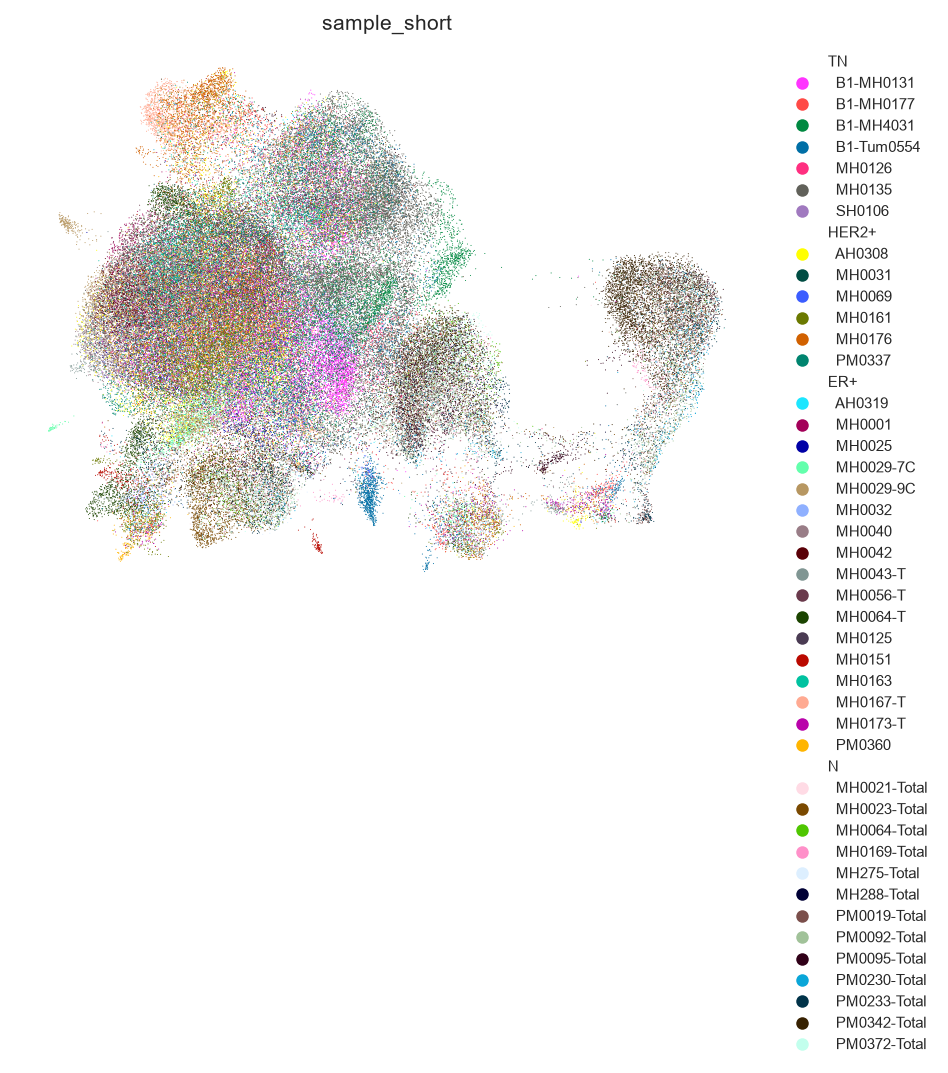

In [307]:
sc.pl.umap(epi, color="sample_short", legend_loc=None, frameon=False, show=False)
ax = plt.gca()
sample_to_color = dict(
    zip(epi.obs["sample_short"].cat.categories, epi.uns["sample_short_colors"])
)
handles = []
for condition in condition_order:
    handles.append(Line2D([], [], linestyle="none", label=condition, color="black"))
    for sample in sorted(
        epi.obs.loc[epi.obs["condition"] == condition, "sample_short"].unique()
    ):
        handles.append(
            Line2D(
                [],
                [],
                marker="o",
                linestyle="none",
                markersize=6,
                markerfacecolor=sample_to_color[sample],
                markeredgecolor="none",
                label=f"  {sample}",
            )
        )
ax.legend(
    handles=handles,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=7,
)
save_umap_figure(plt.gcf(), fig_dir / "epithelial_umap_sample", close=False, overwrite=False)
plt.show()


In [308]:
umap = epi.obsm["X_umap"]


In [309]:
tumour_derived_cnv_high_plot = epi.obs["tumour_derived_cnv_high"].to_numpy()


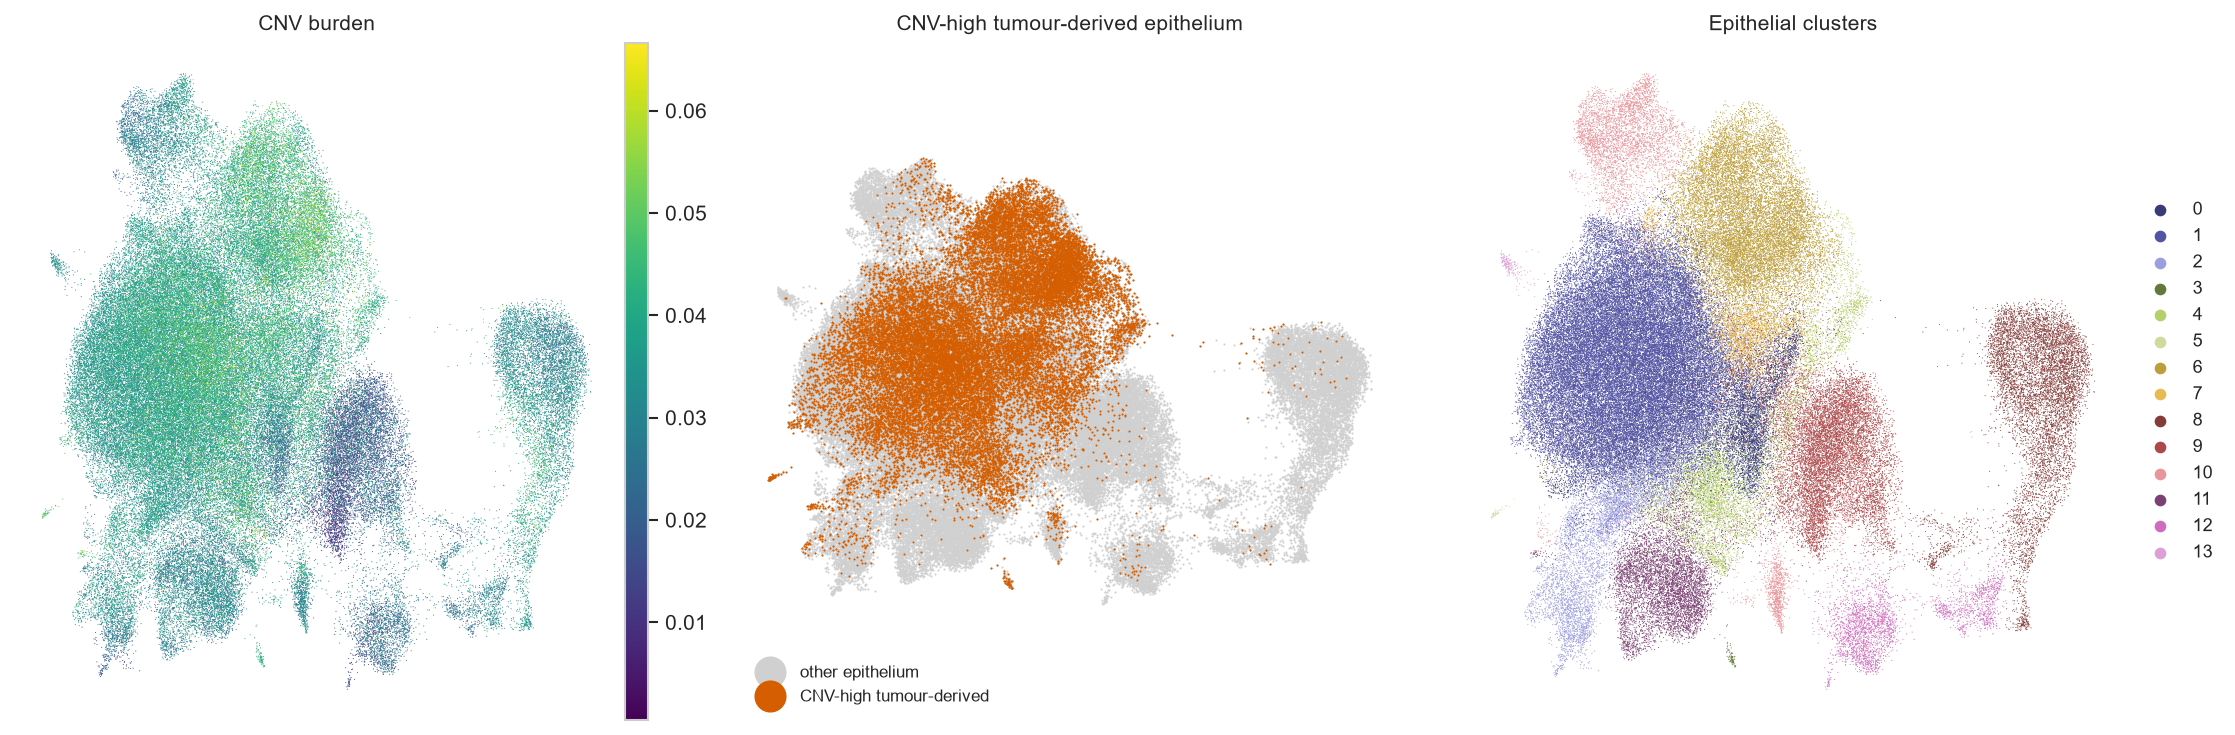

In [310]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sc.pl.umap(
    epi,
    color="cnv_score",
    color_map="viridis",
    vmax="p99.9",
    frameon=False,
    title="CNV burden",
    ax=axes[0],
    show=False,
)
axes[1].scatter(
    umap[:, 0], umap[:, 1], s=1, color="#D0D0D0", linewidths=0, rasterized=True
)
axes[1].scatter(
    umap[tumour_derived_cnv_high_plot, 0],
    umap[tumour_derived_cnv_high_plot, 1],
    s=1,
    color="#D55E00",
    linewidths=0,
    rasterized=True,
)
axes[1].set_title("CNV-high tumour-derived epithelium")
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].set_aspect("equal", adjustable="datalim")
axes[1].set_frame_on(False)
axes[1].legend(
    handles=[
        Line2D(
            [],
            [],
            marker="o",
            linestyle="none",
            color="#D0D0D0",
            label="other epithelium",
        ),
        Line2D(
            [],
            [],
            marker="o",
            linestyle="none",
            color="#D55E00",
            label="CNV-high tumour-derived",
        ),
    ],
    frameon=False,
    loc="lower left",
    markerscale=3,
    fontsize=8,
)
sc.pl.umap(
    epi,
    color="epi_leiden",
    legend_loc="right margin",
    frameon=False,
    title="Epithelial clusters",
    ax=axes[2],
    show=False,
)
fig.tight_layout()
save_umap_figure(fig, fig_dir / "epithelial_umap_population_and_cnv", close=False, overwrite=False)
plt.show()


In [311]:
def save_cnv_panels(epi, output_dir):
    """Standalone CNV panels for figure assembly, using the saved embedding."""
    output_dir = Path(output_dir)
    fig = sc.pl.umap(
        epi,
        color="cnv_score",
        cmap="viridis",
        vmax="p99.9",
        frameon=False,
        title="CNV burden",
        return_fig=True,
        show=False,
    )
    save_umap_figure(
        fig, output_dir / "epithelial_umap_cnv_burden", close=False, overwrite=False
    )
    plt.show()
    coordinates = epi.obsm["X_umap"]
    high = epi.obs["tumour_derived_cnv_high"].to_numpy(bool)
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(*coordinates.T, s=1, color="#D0D0D0", linewidths=0, rasterized=True)
    ax.scatter(
        *coordinates[high].T, s=1, color="#D55E00", linewidths=0, rasterized=True
    )
    ax.set_title("CNV-high tumour-derived epithelium", loc="left")
    ax.set_axis_off()
    ax.legend(
        handles=[
            Line2D(
                [],
                [],
                marker="o",
                linestyle="none",
                color="#D55E00",
                label="tumour-derived, above normal epithelial q95",
            ),
            Line2D(
                [],
                [],
                marker="o",
                linestyle="none",
                color="#D0D0D0",
                label="other epithelial cells",
            ),
        ],
        frameon=False,
        fontsize=8,
        loc="lower left",
    )
    save_umap_figure(
        fig, output_dir / "epithelial_umap_cnv_high", close=False, overwrite=False
    )
    plt.show()


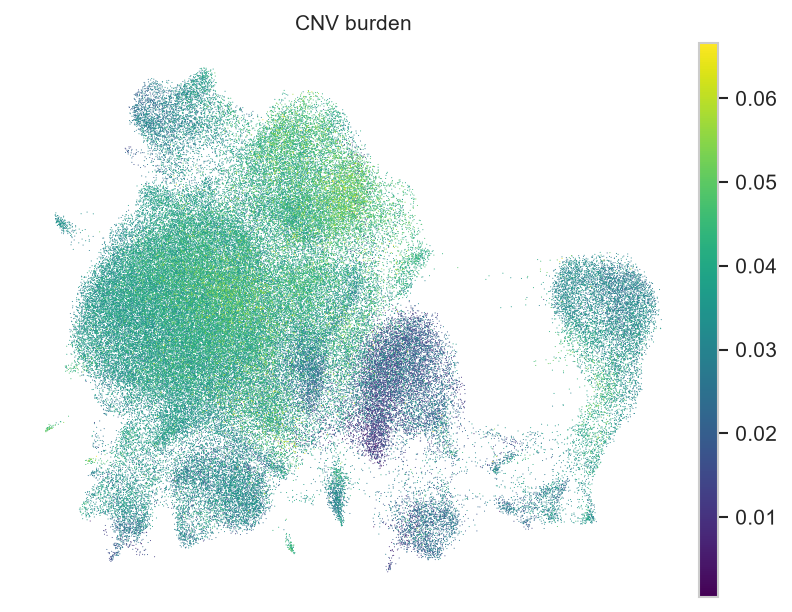

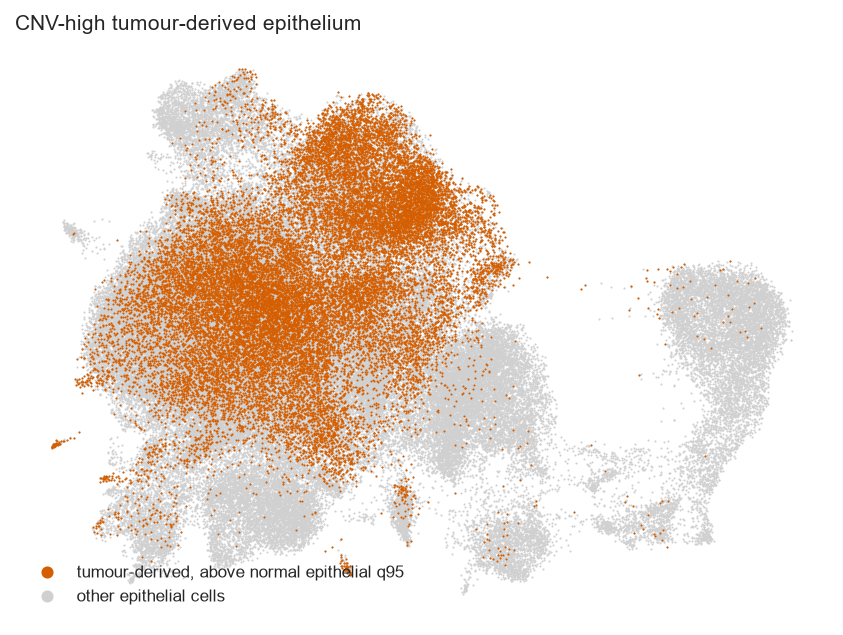

In [312]:
save_cnv_panels(epi, fig_dir)


In [313]:
origin_palette = {
    "normal-tissue epithelium": "#56B4E9",
    "tumour-derived epithelium": "#D55E00",
}


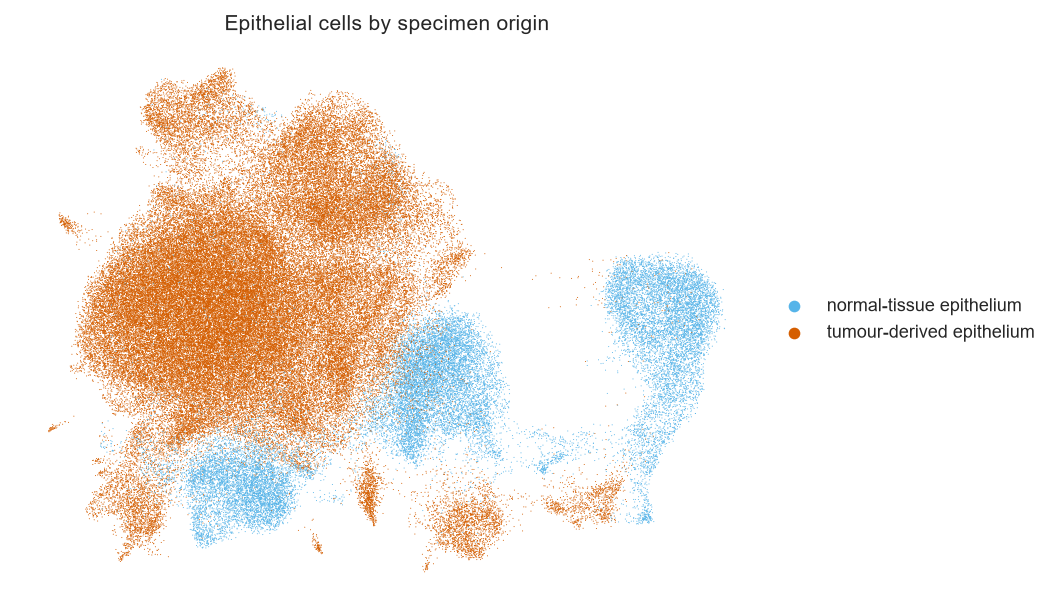

In [314]:
sc.pl.umap(
    epi,
    color="specimen_origin",
    palette=origin_palette,
    frameon=False,
    show=False,
    title="Epithelial cells by specimen origin",
)
save_umap_figure(plt.gcf(), fig_dir / "epithelial_umap_specimen_origin", close=False, overwrite=False)
plt.show()


## Feature-set sensitivity

The primary scVI model uses only the deviance-ranked genes. A second model adds
the antigen and meta-programme genes to test whether that targeted feature choice changes
the neighbourhood or cluster structure beyond ordinary run-to-run variation.

In [315]:
epi_protected = epi[:, epi.var["highly_variable_protected"]].copy()


In [316]:
assert epi_protected.n_vars == n_hvg_protected


In [317]:
scvi.model.SCVI.setup_anndata(epi_protected, layer="counts", batch_key="sample")


In [318]:
model_protected = scvi.model.SCVI(
    epi_protected, n_latent=n_latent, n_layers=n_layers, gene_likelihood=gene_likelihood
)


In [319]:
model_protected.train(
    max_epochs=400, accelerator=scvi_accelerator, batch_size=1024,
    early_stopping=True, early_stopping_patience=20, early_stopping_min_delta=1.0)


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
D:\Conda\envs\cap-rerun\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
D:\Conda\envs\cap-rerun\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
D:\Conda\envs\cap-rerun\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider inc

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Monitored metric elbo_validation did not improve in the last 20 records. Best score: 2950.925. Signaling Trainer to stop.


In [320]:
epi.obsm["X_scVI_protected"] = model_protected.get_latent_representation()


In [321]:
model_protected.save(str(models_dir / "scvi_epithelial_protected_model"), overwrite=False)


In [322]:
del model_protected


In [323]:
gc.collect()


110774

In [324]:
sc.pp.neighbors(
    epi,
    use_rep="X_scVI_protected",
    n_neighbors=n_neighbors,
    random_state=random_seed,
    key_added="protected_neighbors",
)


computing neighbors
    finished (0:00:41)


In [325]:
sc.tl.leiden(
    epi,
    resolution=primary_resolution,
    key_added="epi_leiden_protected",
    neighbors_key="protected_neighbors",
    flavor="igraph",
    n_iterations=2,
    directed=False,
    random_state=random_seed,
)


running Leiden clustering
    finished (0:00:18)


In [326]:
del epi_protected


In [327]:
gc.collect()


782

In [328]:
epi_seed = epi[:, epi.var["highly_variable"]].copy()


In [329]:
scvi.settings.seed = random_seed + 1


Seed set to 1


In [330]:
scvi.model.SCVI.setup_anndata(epi_seed, layer="counts", batch_key="sample")


In [331]:
model_seed = scvi.model.SCVI(
    epi_seed, n_latent=n_latent, n_layers=n_layers, gene_likelihood=gene_likelihood
)


In [332]:
model_seed.train(
    max_epochs=400,
    accelerator=scvi_accelerator,
    batch_size=1024,
    early_stopping=True,
    early_stopping_patience=20,
    early_stopping_min_delta=1.0,
)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
D:\Conda\envs\cap-rerun\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
D:\Conda\envs\cap-rerun\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=15` in the `DataLoader` to improve performance.
D:\Conda\envs\cap-rerun\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider inc

Training:   0%|          | 0/400 [00:00<?, ?it/s]

Monitored metric elbo_validation did not improve in the last 20 records. Best score: 2814.957. Signaling Trainer to stop.


In [333]:
epi.obsm["X_scVI_seed2"] = model_seed.get_latent_representation()


In [334]:
model_seed.save(str(models_dir / "scvi_epithelial_seed2_model"), overwrite=False)


In [335]:
scvi.settings.seed = random_seed


Seed set to 0


In [336]:
sc.pp.neighbors(
    epi,
    use_rep="X_scVI_seed2",
    n_neighbors=n_neighbors,
    random_state=random_seed,
    key_added="seed2_neighbors",
)


computing neighbors
    finished (0:00:15)


In [337]:
sc.tl.leiden(
    epi,
    resolution=primary_resolution,
    key_added="epi_leiden_seed2",
    neighbors_key="seed2_neighbors",
    flavor="igraph",
    n_iterations=2,
    directed=False,
    random_state=random_seed,
)


running Leiden clustering
    finished (0:00:34)


In [338]:
del epi_seed, model_seed


In [339]:
gc.collect()


3027

In [340]:
k_overlap = n_neighbors


In [341]:
overlap_idx = eval_idx


In [342]:
def knn_indices(representation):
    values = epi.obsm[representation][overlap_idx]
    model_nn = NearestNeighbors(n_neighbors=k_overlap + 1).fit(values)
    return model_nn.kneighbors(values, return_distance=False)[:, 1:]


In [343]:
primary_neighbors = knn_indices("X_scVI")


In [344]:
comparisons = [
    ("protected feature set", "X_scVI_protected", "epi_leiden_protected"),
    ("different seed", "X_scVI_seed2", "epi_leiden_seed2"),
]


In [345]:
rows = []


In [346]:
for label, representation, clustering in comparisons:
    other_neighbors = knn_indices(representation)
    overlap = np.array(
        [
            len(set(left) & set(right)) / k_overlap
            for left, right in zip(primary_neighbors, other_neighbors)
        ]
    )
    rows.append(
        {
            "comparison": label,
            "leiden_ari": adjusted_rand_score(
                epi.obs["epi_leiden"], epi.obs[clustering]
            ),
            "leiden_nmi": normalized_mutual_info_score(
                epi.obs["epi_leiden"], epi.obs[clustering]
            ),
            "knn_overlap_mean": overlap.mean(),
            "knn_overlap_median": np.median(overlap),
            "n_clusters": epi.obs[clustering].nunique(),
        }
    )


In [347]:
latent_comparison = pd.DataFrame(rows)


In [348]:
latent_comparison.to_csv(df_dir / "scvi_latent_comparison.csv", index=False)


In [349]:
display(latent_comparison.round(3))


,comparison,leiden_ari,leiden_nmi,knn_overlap_mean,knn_overlap_median,n_clusters
0,protected feature set,0.640,0.644,0.374,0.367,14
1,different seed,0.612,0.646,0.387,0.367,16


In [350]:
rows = []


In [351]:
for label, representation in [
    ("primary_deviance", "X_scVI"),
    ("protected_sensitivity", "X_scVI_protected"),
    ("primary_second_seed", "X_scVI_seed2"),
]:
    values = epi.obsm[representation][eval_idx]
    rows.append(
        {
            "model": label,
            "annotation_silhouette": (
                silhouette_score(values, obs_eval["cl_annotation"])
                if obs_eval["cl_annotation"].nunique() > 1 else np.nan
            ),
            "sample_silhouette": silhouette_score(values, obs_eval["sample"]),
            "condition_silhouette": silhouette_score(
                values, obs_eval["condition"].astype(str)
            ),
        }
    )


In [352]:
model_comparison = pd.DataFrame(rows)


In [353]:
display(model_comparison.round(3))


,model,annotation_silhouette,sample_silhouette,condition_silhouette
0,primary_deviance,0.014,-0.072,0.007
1,protected_sensitivity,0.015,-0.074,0.008
2,primary_second_seed,0.018,-0.072,0.012


In [354]:
del model


In [355]:
gc.collect()


0

In [356]:
rows = []


In [357]:
for annotation in obs_eval["cl_annotation"].value_counts().index:
    mask = obs_eval["cl_annotation"].eq(annotation).to_numpy()
    if mask.sum() < 100 or obs_eval.loc[mask, "sample"].nunique() < 2:
        continue
    row = {"cl_annotation": annotation, "n_cells": int(mask.sum())}
    for label, representation in [
        ("primary_deviance", "X_scVI"),
        ("protected_sensitivity", "X_scVI_protected"),
        ("primary_second_seed", "X_scVI_seed2"),
    ]:
        row[label] = silhouette_score(
            epi.obsm[representation][eval_idx][mask], obs_eval.loc[mask, "sample"]
        )
    rows.append(row)


In [358]:
within_annotation = pd.DataFrame(rows)


In [359]:
display(within_annotation.round(3))


,cl_annotation,n_cells,primary_deviance,protected_sensitivity,primary_second_seed
0,Epithelial: Mature Luminal,7403,-0.063,-0.071,-0.065
1,Epithelial: Luminal,4203,-0.027,-0.025,-0.030
2,Epithelial: Cycling,2670,-0.132,-0.122,-0.131
3,Epithelial,1980,-0.092,-0.090,-0.088
4,Epithelial: Basal/Myoepithelial,1941,-0.086,-0.099,-0.083
5,Epithelial: Luminal Progenitor,1803,-0.078,-0.082,-0.069


In [360]:
cluster_overlap = pd.crosstab(epi.obs["epi_leiden"], epi.obs["epi_leiden_protected"])


In [361]:
best_match = cluster_overlap.max(axis=1) / cluster_overlap.sum(axis=1)


In [362]:
feature_effect = latent_comparison.iloc[0]


In [363]:
seed_floor = latent_comparison.iloc[1]


In [364]:
epi.uns["protected_gene_sensitivity"] = {
    "primary_features": int(n_hvg_deviance),
    "protected_features": int(n_hvg_protected),
    "protected_added": int(n_protected_added),
    "feature_set_ari": float(feature_effect["leiden_ari"]),
    "seed_floor_ari": float(seed_floor["leiden_ari"]),
    "feature_set_knn_overlap": float(feature_effect["knn_overlap_mean"]),
    "seed_floor_knn_overlap": float(seed_floor["knn_overlap_mean"]),
    "k": int(k_overlap),
}


In [365]:
model_comparison.to_csv(df_dir / "scvi_feature_sensitivity.csv", index=False)


In [366]:
within_annotation.to_csv(
    df_dir / "scvi_feature_sensitivity_by_annotation.csv", index=False
)


In [367]:
best_match.rename("largest_matching_fraction").to_csv(
    df_dir / "scvi_feature_cluster_correspondence.csv"
)


## Save

In [368]:
final_positive = {
    gene: int((np.asarray(epi[:, gene].layers["counts"].todense()).ravel() > 0).sum())
    for gene in target_genes
}


In [369]:
assert epi.n_obs == n_cells_start


In [370]:
assert epi.n_vars == n_genes_start


In [371]:
assert final_positive == {gene: baseline_positive[gene] for gene in final_positive}


In [372]:
epi.uns["epithelial_integration"] = {
    "hvg_method": "binomial deviance (scry), maximum across samples",
    "primary_feature_set": "deviance-ranked genes only",
    "n_hvg_primary": int(n_hvg_deviance),
    "n_hvg_protected_sensitivity": int(n_hvg_protected),
    "scvi_n_latent": int(n_latent),
    "scvi_n_layers": int(n_layers),
    "scvi_gene_likelihood": gene_likelihood,
    "scvi_batch_key": "sample",
    "scvi_epochs": int(n_epochs),
    "n_neighbors": int(n_neighbors),
    "leiden_resolutions": [float(value) for value in leiden_resolutions],
    "leiden_primary": float(primary_resolution),
    "seed": int(random_seed),
}


In [373]:
out_path = save_dir / "epithelial_tumour_scvi.h5ad"


In [374]:
for name in list(epi.layers.keys()):
    if not sp.issparse(epi.layers[name]):
        epi.layers[name] = sp.csr_matrix(epi.layers[name])


In [375]:
if not sp.issparse(epi.X):
    epi.X = sp.csr_matrix(epi.X)


In [376]:
tmp_path = out_path.with_suffix(".h5ad.tmp")


In [377]:
if out_path.exists():
    raise FileExistsError("Analysis output already exists; choose a new run_dir for a fresh analysis.")


In [378]:
epi.write_h5ad(tmp_path, compression="gzip")


In [379]:
os.replace(tmp_path, out_path)


In [380]:
display(pd.DataFrame({"saved": [out_path.name]}))


,saved
0,epithelial_tumour_scvi.h5ad


In [381]:
check = sc.read_h5ad(out_path, backed="r")


In [382]:
assert check.n_obs == epi.n_obs


In [383]:
assert check.n_vars == epi.n_vars


In [384]:
check.shape


(123382, 27292)

In [385]:
del check


In [386]:
gc.collect()


0

In [387]:
session_info.show()


D:\Conda\envs\cap-rerun\Lib\site-packages\session_info\main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  mod_version = _find_version(mod.__version__)
D:\Conda\envs\cap-rerun\Lib\site-packages\session_info\main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  mod_version = _find_version(mod.__version__)
